# Профилирование инференса

Сравним eager и FlashAttention, проведём граф через ONNX Runtime и TensorRT, затем измерим генерацию текста в vLLM. Для каждого шага посмотрим время, память и трассу.

## Что сегодня разберём

1. [Подготовка](#0.-%D0%9F%D0%BE%D0%B4%D0%B3%D0%BE%D1%82%D0%BE%D0%B2%D0%BA%D0%B0) — CUDA, зависимости и просмотр трасс.
2. [Механизм внимания](#%D0%9C%D0%B5%D1%85%D0%B0%D0%BD%D0%B8%D0%B7%D0%BC-%D0%B2%D0%BD%D0%B8%D0%BC%D0%B0%D0%BD%D0%B8%D1%8F) — Q/K/V, каузальная маска, eager-реализация и её затраты.
3. [FlashAttention на Triton](#%D0%A1%D0%B2%D0%BE%D1%91-GPU-%D1%8F%D0%B4%D1%80%D0%BE-%D0%BD%D0%B0-Triton) — сравнение с CUDA C++, `@triton.jit`, сетка запуска и блочный softmax.
4. [Профилирование](#2.-%D0%92%D1%80%D0%B5%D0%BC%D1%8F,-%D0%BF%D0%B0%D0%BC%D1%8F%D1%82%D1%8C-%D0%B8-%D1%82%D1%80%D0%B0%D1%81%D1%81%D0%B0) — прогрев, p50/p95, расход памяти и события GPU.
5. [От ONNX к TensorRT](#3.-%D0%9E%D1%82-ONNX-%D0%BA-TensorRT) — экспорт, оптимизация графов, сравнение с ONNX Runtime и разбор engine.
6. [Генерация в vLLM](#4.-%D0%93%D0%B5%D0%BD%D0%B5%D1%80%D0%B0%D1%86%D0%B8%D1%8F-%D1%82%D0%B5%D0%BA%D1%81%D1%82%D0%B0-%D0%BF%D0%BE%D0%B4-%D0%BD%D0%B0%D0%B3%D1%80%D1%83%D0%B7%D0%BA%D0%BE%D0%B9) — prefill/decode, continuous batching, speculative decoding, TTFT и throughput.
7. [Разбор результатов](#5.-%D0%A7%D1%82%D0%BE-%D0%B8%D0%B7%D0%BC%D0%B5%D0%BD%D0%B8%D0%BB%D0%BE%D1%81%D1%8C?) — сравнение реализаций по задержке, памяти и пропускной способности.

## 0. Подготовка

Для полного прогона нужны CUDA-сборка PyTorch и NVIDIA GPU Ampere или новее. Ноутбук проверен на H100.

Зависимости: `torch`, `onnx`, `onnxscript`, `onnxruntime-gpu`, `viztracer`, `triton` (для своего GPU-ядра). Также нужны `tensorrt-cu12` и `vllm`: все разделы выполняются на GPU. Проверенные версии: PyTorch 2.8.0/cu128, ORT 1.23.2, TensorRT 10.0.1, vLLM 0.11.0, Triton 3.4.0.

Ноутбук самодостаточен: файлы сохраняются в `~/inference-results` или каталог из `INFERENCE_OUTPUT_DIR`. Рабочая папка ядра на этот выбор не влияет.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import json
import os
import platform
import shutil
import subprocess
import sys

# Абсолютный каталог не зависит от рабочей папки ядра Jupyter.
OUTPUT_ROOT = Path(os.environ.get("INFERENCE_OUTPUT_DIR", Path.home() / "inference-results")).expanduser()

Проверяем устройство и версии библиотек. `torch.version.cuda` показывает версию CUDA, с которой собран PyTorch; `torch.cuda.is_available()` — может ли эта сборка использовать GPU в текущем процессе.

In [2]:
import torch
import onnx
import onnxruntime as ort

assert torch.cuda.is_available(), "Нужны NVIDIA GPU и PyTorch с поддержкой CUDA."
DEVICE = torch.device("cuda:0")
assert torch.cuda.get_device_capability(DEVICE)[0] >= 8, "Нужен GPU Ampere или новее."
torch.cuda.set_device(DEVICE)
device_name = torch.cuda.get_device_name(DEVICE)
print(f"{device_name} | PyTorch {torch.__version__} | CUDA {torch.version.cuda}")
print(f"ONNX {onnx.__version__} | ORT {ort.__version__}")

2026-11-25 17:59:53.020536824 [W:onnxruntime:Default, device_discovery.cc:164 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:89 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


NVIDIA H100 80GB HBM3 | PyTorch 2.8.0+cu128 | CUDA 12.8
ONNX 1.20.1 | ORT 1.23.2


TensorRT понадобится для сборки ONNX-графа в исполняемый план под GPU. Здесь проверяем импорт библиотеки; само построение движка будет в третьей части.

In [3]:
import tensorrt as trt
print("TensorRT", trt.__version__)

TensorRT 10.0.1


Результаты и трассы одного запуска складываем в отдельный каталог.

In [4]:
from html import escape
from IPython.display import Markdown, SVG, display

def save_json(filename, data):
    """Сохраняет данные в JSON в каталоге текущего прогона."""
    (OUT / filename).write_text(json.dumps(data, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

def read_json(filename):
    """Читает JSON с результатами из каталога текущего прогона."""
    return json.loads((OUT / filename).read_text(encoding="utf-8"))


def show_table(headers, rows):
    """Выводит заголовки и строки как Markdown-таблицу под ячейкой."""
    header = "| " + " | ".join(headers) + " |"
    separator = "| " + " | ".join(["---"] * len(headers)) + " |"
    body = ["| " + " | ".join((escape(str(value)).replace("|", "&#124;") for value in row)) + " |" for row in rows]
    display(Markdown("\n".join([header, separator, *body])))

Для каждого запуска создаём новый каталог и сохраняем сведения об устройстве и библиотеках. Это позволяет сопоставить измерения с окружением, в котором они получены.

In [5]:
stamp = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S-%f")
OUT = (OUTPUT_ROOT / stamp).resolve()
OUT.mkdir(parents=True)
save_json("environment.json", {
    "device": device_name, "torch": str(torch.__version__),
    "cuda": torch.version.cuda, "onnxruntime": ort.__version__,
    "tensorrt": trt.__version__,
})
print("Результаты:", OUT)

Результаты: /home/jovyan/inference-results/20261125-145955-909198


### Разбор сохранённого запуска

Выводы ниже относятся к запуску **25.11.2026, 17:59–18:06 МСК**, `20261125-145955-909198`: H100 80GB, PyTorch 2.8.0+cu128, ORT 1.23.2, TensorRT 10.0.1, vLLM 0.11.0. Числа в этих текстовых ячейках зафиксированы для этого запуска; кодовые ячейки при выполнении получают новые измерения.

[Сводка анализа: исходные метрики, события и хеши файлов](inference-support/analysis/20261125-145955-909198.json).

### Просмотр трасс

Используем HTML-просмотрщик VizTracer без WebAssembly. Масштабируйте шкалу и выбирайте события CPU и GPU. Через ссылки можно скачать исходную трассу и готовый HTML.

Для встраивания нужен `jupyter-server-proxy` на сервере Jupyter или прокси Colab. JS-компонент совместимости загружается один раз; готовый HTML работает без сети.

In [6]:
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from tempfile import TemporaryDirectory
from threading import Thread
from urllib.parse import quote
from IPython.display import IFrame

class ViewerHandler(SimpleHTTPRequestHandler):
    def log_message(self, *args):
        """Скрывает журнал HTTP-запросов из вывода занятия."""

Просмотрщик работает через локальный HTTP-сервер в отдельном потоке. Поэтому отображение временной шкалы не блокирует выполнение следующих ячеек.

In [7]:
def start_viewer():
    """Запускает HTTP-сервер для HTML-отчётов и исходных трасс во временной папке."""
    temp = TemporaryDirectory()
    (Path(temp.name) / "traces").mkdir()
    server = ThreadingHTTPServer(("127.0.0.1", 0), partial(ViewerHandler, directory=temp.name))
    Thread(target=server.serve_forever, daemon=True).start()
    return temp, server

# Перезапуск этой ячейки заменяет старый просмотрщик и его временные файлы.
if "trace_server" in globals():
    trace_server.shutdown()
    trace_server.server_close()
    viewer_files.cleanup()
viewer_files, trace_server = start_viewer()

In [8]:
TRACE_VIEWER_BASE_URL = os.environ.get("INFERENCE_VIEWER_BASE_URL", "")

def trace_urls(origin, relative):
    """Возвращает URL готового HTML и исходной трассы с учётом префикса прокси."""
    trace_url = f"{origin.rstrip('/')}/traces/{quote(relative)}"
    return trace_url + ".html", trace_url

In [9]:
def viewer_polyfill():
    """Читает из кеша JS-компонент совместимости; загружает его при первом запуске."""
    from urllib.request import urlopen
    cache = OUTPUT_ROOT / ".viewer-assets" / "webcomponents-0.7.24.min.js"
    if not cache.is_file():
        cache.parent.mkdir(parents=True, exist_ok=True)
        url = "https://cdnjs.cloudflare.com/ajax/libs/webcomponentsjs/0.7.24/webcomponents.min.js"
        with urlopen(url, timeout=30) as response:
            cache.write_bytes(response.read())
    return cache.read_text(encoding="utf-8")

PyTorch и vLLM сохраняют события в поле `traceEvents`, а ONNX Runtime — списком. Приводим эти форматы к общей структуре и встраиваем данные в HTML, который можно открыть отдельно от ноутбука.

In [10]:
def build_trace_html(path, output):
    """Создаёт HTML с данными трассы и встроенными скриптами, без WebAssembly."""
    import gzip
    import re
    from viztracer.report_builder import ReportBuilder
    opener = gzip.open if path.suffix == ".gz" else open
    with opener(path, "rt", encoding="utf-8") as handle:
        data = json.load(handle)
    # ORT пишет список событий, PyTorch и vLLM — словарь с traceEvents.
    if isinstance(data, list):
        data = {"traceEvents": data}
    ReportBuilder(data, verbose=0).save(str(output), file_info=False)
    # Встраиваем polyfill; подсветка исходников Prism для временной шкалы не нужна.
    polyfill = "<script>" + viewer_polyfill() + "</script>"
    html = re.sub(r'<script[^>]+src="[^"]+"[^>]*></script>',
                  lambda tag: polyfill if "webcomponents" in tag[0] else "", output.read_text(encoding="utf-8"))
    output.write_text(html, encoding="utf-8")

In [11]:
def proxy_viewer(port, relative):
    """Встраивает HTML-трассу и ссылки на скачивание через прокси текущего Jupyter."""
    from IPython.display import HTML
    from uuid import uuid4
    tag = "trace-" + uuid4().hex
    trace_path = json.dumps("traces/" + quote(relative))
    prefix = json.dumps(os.environ.get("JUPYTERHUB_SERVICE_PREFIX", "/"))
    # Внешний адрес Jupyter за прокси определяем в браузере, а не в Python.
    display(HTML(f"""
    <div id="{tag}">Подключаем просмотрщик…</div>
    <script>(async () => {{
      const box = document.getElementById("{tag}");
      try {{
        const node = document.getElementById("jupyter-config-data");
        const config = node ? JSON.parse(node.textContent) : {{}};
        const base = config.baseUrl || document.body.dataset.baseUrl || {prefix};
        const proxy = new URL("proxy/{port}/", new URL(base, location.origin));
        const trace = new URL({trace_path}, proxy), html = trace.href + ".html";
        const response = await fetch(html, {{credentials: "same-origin"}});
        if (!response.ok) throw new Error("HTTP " + response.status);
        const frame = document.createElement("iframe");
        frame.src = html; frame.style = "width:100%;height:580px;border:0";
        box.replaceChildren(frame);
        for (const [label, url] of [["Скачать HTML", html], ["Скачать трассу", trace]]) {{
          const link = document.createElement("a");
          link.textContent = label; link.href = url; link.download = "";
          box.append(link, document.createTextNode(" · "));
        }}
      }} catch (e) {{ box.textContent = "Нет прокси: откройте сохранённый HTML-файл. " + e; }}
    }})();</script>"""))

In [12]:
def show_trace(path):
    """Сохраняет HTML-трассу и показывает её через прокси Jupyter или Colab."""
    if not path.is_file():
        raise FileNotFoundError(path)
    relative = path.resolve().relative_to(OUT).as_posix()
    html_path = path.with_name(path.name + ".html")
    build_trace_html(path, html_path)
    link = Path(viewer_files.name) / "traces" / relative
    link.parent.mkdir(parents=True, exist_ok=True)
    for destination, source in [(link, path), (Path(str(link) + ".html"), html_path)]:
        destination.unlink(missing_ok=True)
        destination.symlink_to(source.resolve())
    print("HTML-трасса:", html_path)
    port = trace_server.server_port
    origin = TRACE_VIEWER_BASE_URL.format(port=port)
    if "google.colab" in sys.modules and not origin:
        from google.colab.output import eval_js
        origin = eval_js(f"google.colab.kernel.proxyPort({port})")
    if origin:
        display(IFrame(trace_urls(origin, relative)[0], width="100%", height=580))
    else:
        proxy_viewer(port, relative)

### Механизм внимания

Для одной головы внимания:

$$
O = \operatorname{softmax}\!\left(\frac{QK^{\mathsf T}}{\sqrt{d_k}} + M\right)V,
\qquad
M_{ij} = \begin{cases}
0, & j \le i, \\
-\infty, & j > i.
\end{cases}
$$

$Q$ — запросы, $K$ — ключи, $V$ — значения; $d_k$ — размер головы (`head_dim`).
Матрица $QK^{\mathsf T}$ содержит оценки сходства токенов. Softmax применяется по строкам, а умножение на $V$ даёт взвешенную сумму значений.

Каузальная маска $M$ обнуляет веса будущих токенов. В ноутбуке Q/K/V уже подготовлены: сравниваем способы вычисления этой формулы.

## 1. Каузальное внимание

Входы имеют форму `[batch, heads, tokens, head_dim]`. Меняем длину контекста, сохраняя остальные размеры.

In [13]:
import torch
torch.set_num_threads(1)
import torch.nn.functional as F
from torch.nn.attention import SDPBackend, sdpa_kernel

ATTENTION_LENGTHS = (128, 512, 1024)

def attention_inputs(length):
    """Создаёт воспроизводимые Q, K, V формы [1, 4, length, 64] на DEVICE."""
    generator = torch.Generator(device="cpu").manual_seed(42 + length)
    # [batch, heads, tokens, head_dim]: один пример, четыре головы внимания.
    shape = (1, 4, length, 64)  # Каждая голова использует векторы из 64 компонент.
    return tuple(torch.randn(shape, generator=generator, device="cpu", dtype=torch.float32)
                 .to(device=DEVICE, dtype=torch.float16) for _ in range(3))

Явно строим матрицу оценок QKᵀ. Каузальная маска запрещает смотреть на будущие токены.

In [14]:
def eager_attention(q, k, v, future=None):
    """Каузальное self-attention для тензоров в порядке B, H, L, D."""
    scores = (q @ k.transpose(-2, -1)) * (q.size(-1) ** -0.5)
    if future is None:
        length = q.size(-2)
        future = torch.ones((length, length), device=q.device, dtype=torch.bool).triu(1)
    # После softmax будущие позиции с оценкой −∞ получают нулевой вес.
    weights = scores.masked_fill(future, float("-inf")).softmax(dim=-1)
    return weights @ v

**Где eager-реализация расходует ресурсы**

- **Память:** `scores` и `weights` имеют форму `[B, H, L, L]`. При удвоении L каждая матрица увеличивается в четыре раза. Для `B=1`, `H=4`, `L=1024` одна такая матрица в FP16 занимает **8 МиБ**.
- **Обмен с памятью:** масштабирование, маска и softmax читают и записывают промежуточные матрицы в глобальную память GPU (HBM). Это добавляет обмен данными между этапами.
- **Запуски GPU-ядер:** матричные умножения, масштабирование, применение маски и softmax выполняются отдельными операциями. К времени вычислений добавляются расходы на Python-вызовы и запуск ядер.

При `future=None` эта функция также заново создаёт каузальную маску на каждом вызове. В нашей Triton-реализации этапы объединены в одно ядро: оценки и веса обрабатываются блоками, а между блоками сохраняются `m`, `l` и `acc`.

**Эталон и `sdpa_kernel(SDPBackend.MATH)`**

SDPA (*scaled dot-product attention*) — внимание через масштабированное скалярное произведение; в PyTorch его вычисляет `F.scaled_dot_product_attention`. У этой функции есть несколько реализаций, называемых backend.

`sdpa_kernel(SDPBackend.MATH)` — контекстный менеджер: внутри `with` он выбирает стандартную математическую реализацию SDPA. После выхода восстанавливается прежний выбор backend. Устройство определяется входными тензорами: в нашем эталоне они перенесены на CPU и приведены к FP32. [Документация `sdpa_kernel`](https://docs.pytorch.org/docs/2.8/generated/torch.nn.attention.sdpa_kernel.html).

In [15]:
def math_reference(q, k, v):
    """Вычисляет эталон каузального внимания на CPU в FP32 через SDPA math."""
    inputs = [x.to(device="cpu", dtype=torch.float32) for x in (q, k, v)]
    # MATH выбирает обычную математическую реализацию SDPA только внутри этого with.
    with sdpa_kernel(SDPBackend.MATH):
        return F.scaled_dot_product_attention(*inputs, dropout_p=0.0, is_causal=True)

def causal_sdpa(q, k, v):
    """Вычисляет каузальное внимание без dropout через выбранный backend SDPA."""
    return F.scaled_dot_product_attention(q, k, v, dropout_p=0.0, is_causal=True)

### Своё GPU-ядро на Triton

**Triton** — язык с Python-подобным синтаксисом и компилятор для написания своих GPU-ядер. Ядро (*kernel*) — функция, которая параллельно обрабатывает данные на GPU. Операции над блоками тензоров описываем через `triton.language` (`tl`), а компилятор переводит их в машинный код GPU. [Документация Triton](https://triton-lang.org/main/index.html).

Своё ядро позволяет объединить несколько операций в один запуск и сократить обмен с глобальной памятью. В нашем FlashAttention вычисление оценок, softmax и умножение на V выполняются внутри одного ядра.

**Почему Triton проще CUDA C++**

| Что описываем | CUDA C++ | Triton |
| --- | --- | --- |
| Параллельную работу | Действия отдельных потоков и их индексы | Операции над целым блоком тензора |
| Обмен данными внутри блока | Часто явно управляем shared memory и синхронизацией | Компилятор организует размещение данных и синхронизацию |
| Суммы и матричные произведения | Организуем совместную работу потоков или используем библиотеки | Вызываем `tl.sum`, `tl.max`, `tl.dot` |

Для таких тензорных ядер Triton гораздо проще: меньше кода для потоков, памяти и синхронизации, а запись ближе к формулам. Компилятор распределяет операции по потокам и выбирает инструкции GPU. Размеры блоков, маски и порядок обхода всё равно выбираем мы; скорость проверяем измерениями. [Модель программирования Triton и сравнение с CUDA](https://triton-lang.org/main/programming-guide/chapter-1/introduction.html).

**Что реализуем**

Реализуем прямой проход FlashAttention: блок Q остаётся на GPU, а блоки K и V читаются по очереди. Полную матрицу внимания L × L в глобальную память не записываем.

Одна программа Triton обрабатывает 32 строки Q одной головы. `tl.arange` задаёт индексы внутри блока, `tl.load/store` читают и записывают память, `tl.dot` выполняет матричное умножение.

Одна строка Q — запрос одного токена одной головы. У каждой строки свой softmax по ключам. Для строки $r$ обозначим через $J_r$ уже просмотренные ключи, разрешённые каузальной маской, а через $s_{rj}$ — оценки сходства Q и K.

| Переменная | Что храним для строки $r$ | Форма в нашем ядре |
| --- | --- | --- |
| `m` | $m_r=\max_{j\in J_r}s_{rj}$ — текущий максимум оценок; его вычитаем для устойчивого вычисления экспонент | `(32,)`: одно число на каждый из 32 запросов |
| `l` | $l_r=\sum_{j\in J_r}\exp(s_{rj}-m_r)$ — сумма ненормированных весов, знаменатель softmax | `(32,)`: одно число на запрос |
| `acc` | $\mathrm{acc}_r=\sum_{j\in J_r}\exp(s_{rj}-m_r)V_j$ — числитель, взвешенная сумма векторов V | `(32, D)`: вектор из D чисел на запрос |

Все три накопителя — FP32. `l` (строчная латинская L) — сумма весов; `L` в коде — длина последовательности.

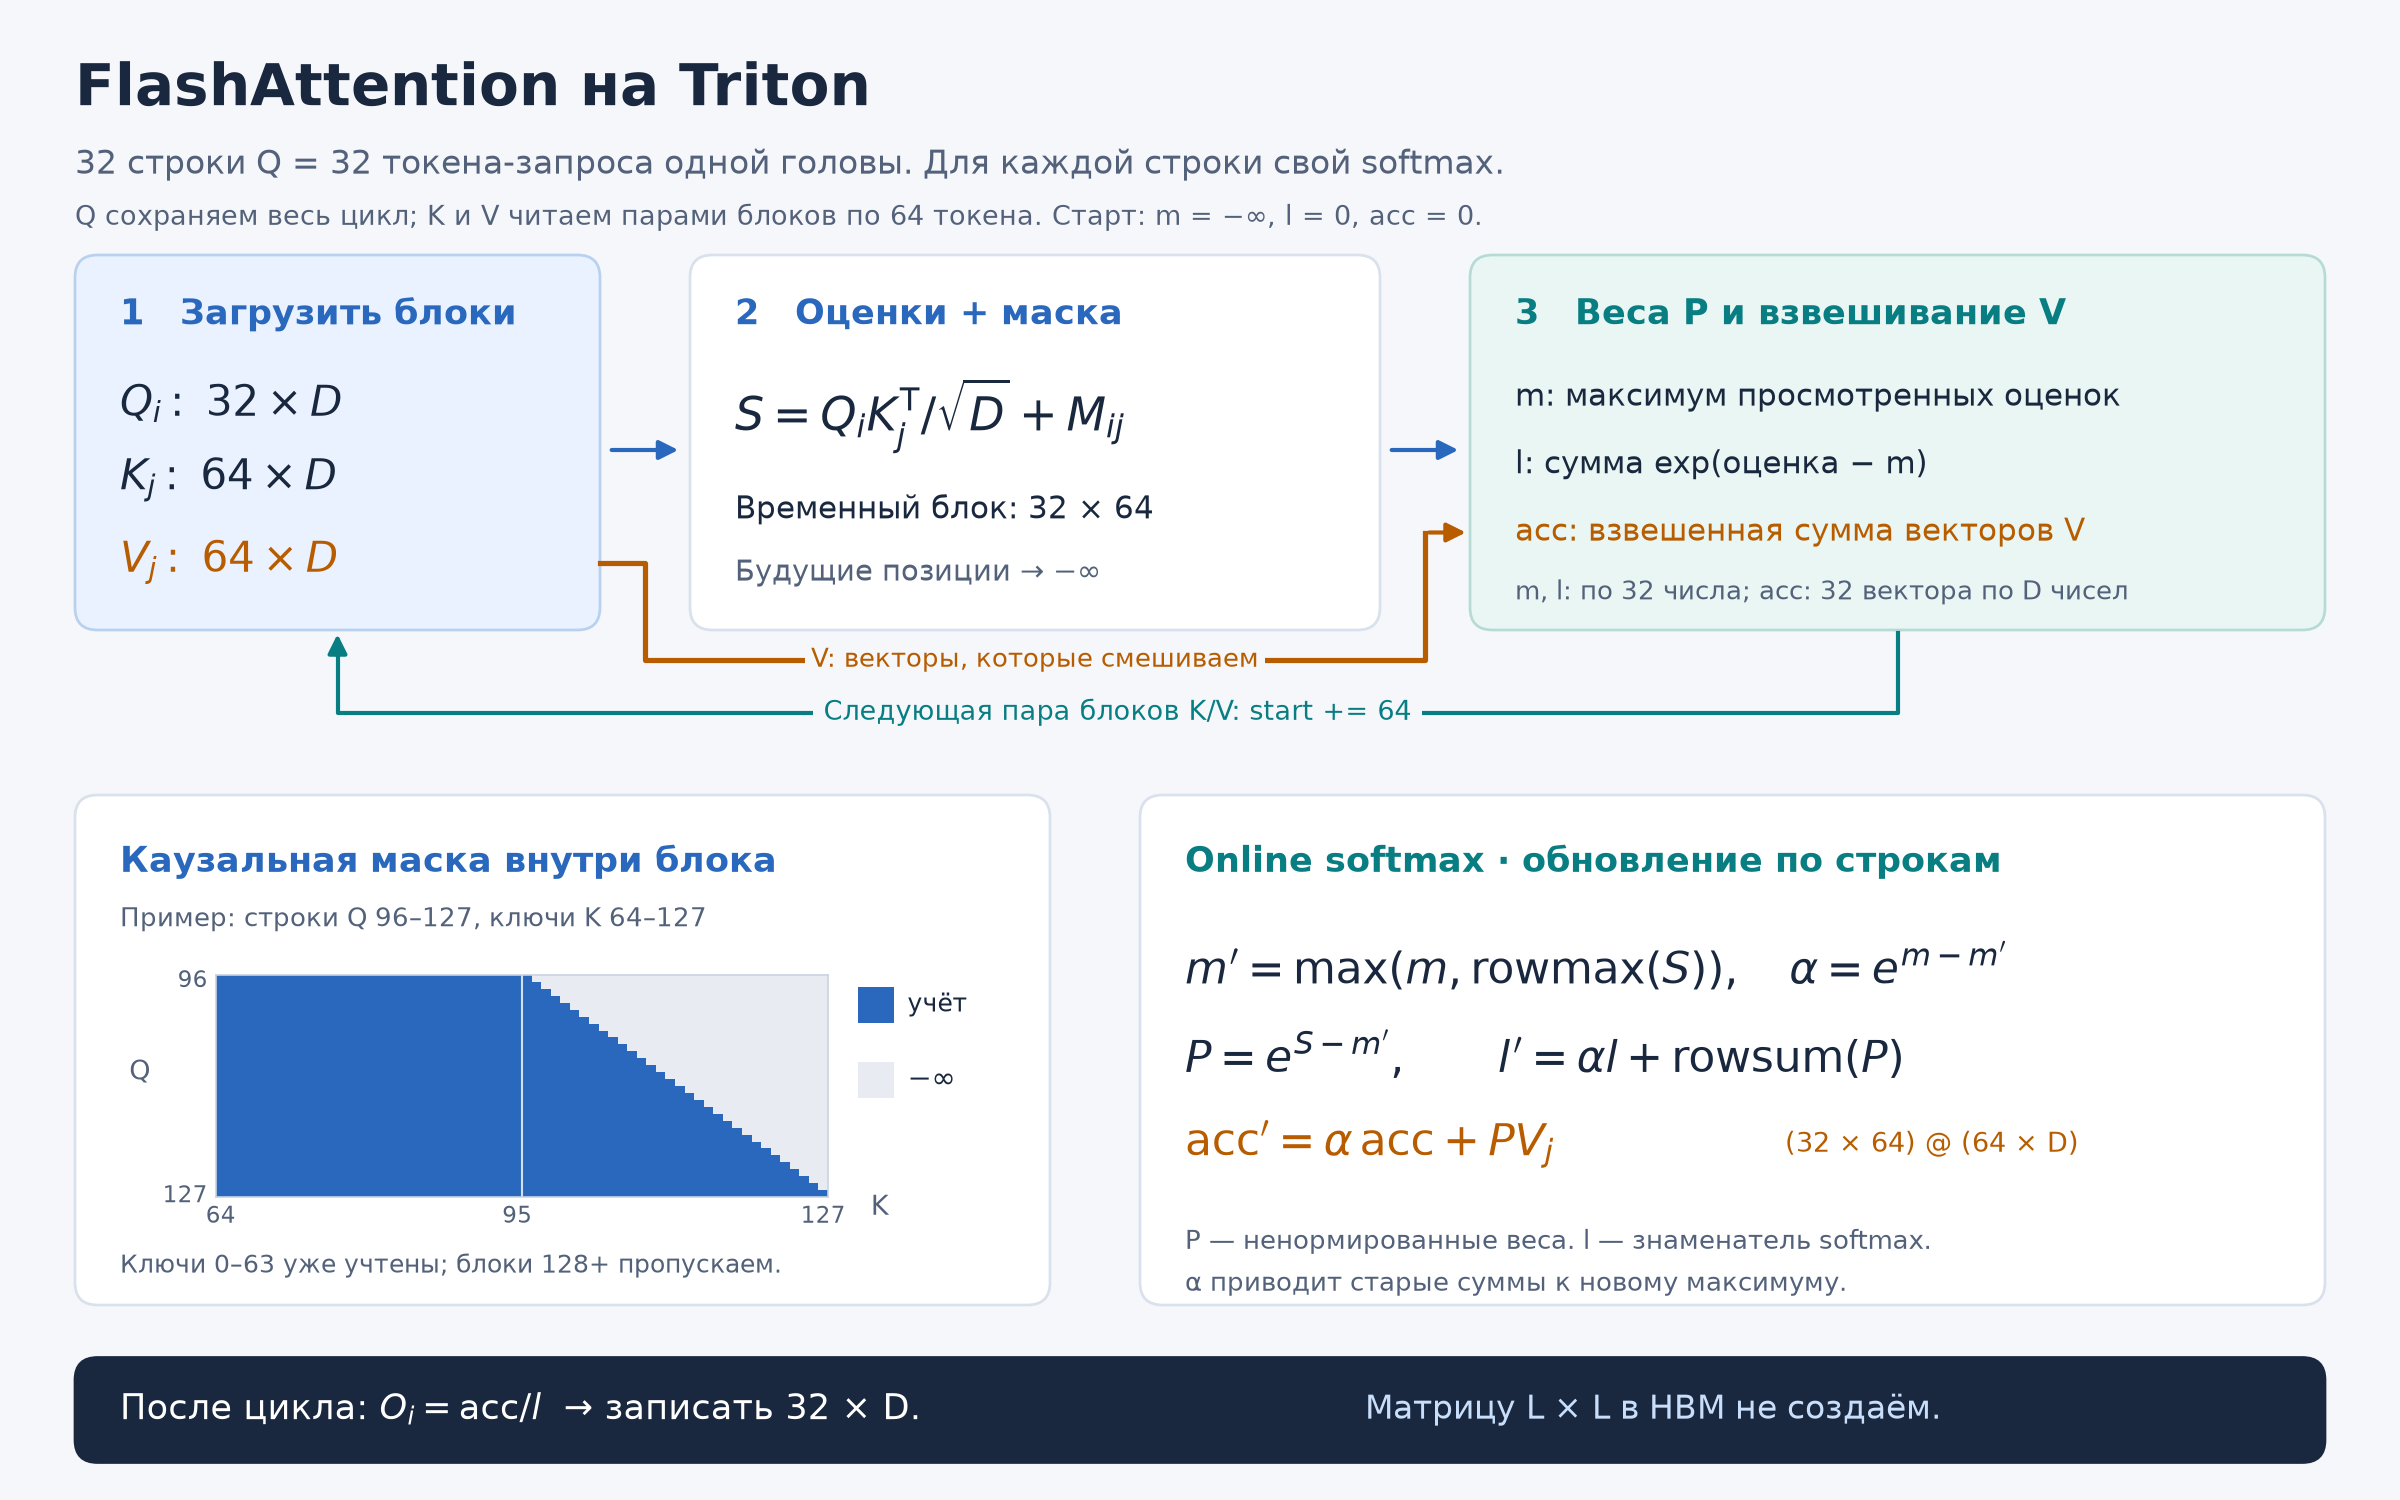

**Как участвует V**

Q и K определяют, с каким весом учитывать каждый токен. V содержит векторы, из которых собирается выход: каждый вес умножается на соответствующий вектор V, затем эти векторы суммируются.

В нашем коде `P` называется `weights`. Умножение `tl.dot(weights, values)` имеет размеры **`(32, 64) @ (64, D) → (32, D)`**: для каждого из 32 запросов смешиваем 64 вектора V. Это вклад блока в `acc`. Веса пока не нормированы, поэтому после всех блоков делим каждую строку `acc` на её `l`: $O_r=\mathrm{acc}_r/l_r$.

Минипример для одной строки: при $V_1=(3,0)$, $V_2=(0,3)$ и весах $(0.5,1)$ получаем $\mathrm{acc}=(1.5,3)$, $l=1.5$ и выход $O=(1,2)$.

In [16]:
import triton
import triton.language as tl
print("Triton", triton.__version__)

Triton 3.4.0


**Что делает декоратор `@triton.jit`**

Декоратор перед `def` передаёт функцию компилятору Triton. JIT означает *just-in-time*: компиляция по запросу. При объявлении сохраняется описание функции; вычисления запускаются при вызове ядра.

1. Вызов `kernel[grid](...)` задаёт сетку программ и запускает ядро. При первом запуске Triton компилирует нужный вариант под GPU, типы аргументов и параметры `tl.constexpr`, например `D`, `BLOCK_M`, `BLOCK_N`.
2. Скомпилированный вариант кешируется. Повторные вызовы используют его; изменение параметров специализации может потребовать компиляции нового варианта. Поэтому первый вызов выполняем до измерений времени.
3. Тело функции работает на GPU и использует операции `tl`, поддерживаемые конструкции Python и другие JIT-функции. Это отдельный язык вычислений: произвольный Python-код или вызовы PyTorch внутрь ядра перенести нельзя.

У нас `_triton_softmax_step` и `_triton_attention_tile` встраиваются в `_triton_flash_forward`. Декоратор на каждой вспомогательной функции позволяет вызвать её из GPU-кода; отдельного запуска GPU для каждой функции нет. [Описание `triton.jit`](https://triton-lang.org/main/python-api/generated/triton.jit.html), [пример запуска `kernel[grid](...)`](https://triton-lang.org/main/getting-started/tutorials/01-vector-add.html).

**Softmax по частям.** Новый блок ключей может повысить максимум с `m` до `new_m`. Чтобы старые и новые веса были в одном масштабе, умножаем прежние `l` и `acc` на `alpha = exp(m - new_m)`, затем добавляем вклад нового блока. В конце `acc / l[:, None]` нормирует каждый выходной вектор своим знаменателем.

In [17]:
@triton.jit
def _triton_softmax_step(scores, values, m, l, acc):
    """Обновляет максимум, сумму экспонент и сумму V после одного блока ключей."""
    new_m = tl.maximum(m, tl.max(scores, axis=1))
    alpha = tl.exp(m - new_m)
    weights = tl.exp(scores - new_m[:, None])
    # Накопленные суммы приводим к новому масштабу; аккумуляторы остаются FP32.
    l = l * alpha + tl.sum(weights, axis=1)
    acc = acc * alpha[:, None] + tl.dot(weights.to(tl.float16), values)
    return new_m, l, acc

Загружаем один блок K/V. Маска одновременно отсекает будущие токены и позиции за концом последовательности.

In [18]:
@triton.jit
def _triton_attention_tile(q, K, V, base, rows, dims, start, m, l, acc,
                           L: tl.constexpr, D: tl.constexpr, BLOCK_N: tl.constexpr):
    """Читает блок K/V и добавляет его вклад в каузальное внимание для строк Q."""
    cols = start + tl.arange(0, BLOCK_N)
    k = tl.load(K + base + cols[None, :] * D + dims[:, None],
                mask=cols[None, :] < L, other=0)
    v = tl.load(V + base + cols[:, None] * D + dims[None, :],
                mask=cols[:, None] < L, other=0)
    scores = tl.dot(q, k) * (D ** -0.5)
    allowed = (rows[:, None] >= cols[None, :]) & (cols[None, :] < L)
    scores = tl.where(allowed, scores, float("-inf"))
    return _triton_softmax_step(scores, v, m, l, acc)

Сетка запуска двумерная: по блокам строк Q и по парам «элемент батча, голова». Все вспомогательные функции встраиваются в этот kernel; отдельных запусков softmax и умножения на V нет.

In [19]:
@triton.jit
def _triton_flash_forward(Q, K, V, O, L: tl.constexpr, D: tl.constexpr,
                          BLOCK_M: tl.constexpr, BLOCK_N: tl.constexpr):
    """Вычисляет блок строк каузального внимания и записывает только готовый выход."""
    rows = tl.program_id(0) * BLOCK_M + tl.arange(0, BLOCK_M)
    dims = tl.arange(0, D)
    base = tl.program_id(1) * L * D
    offsets = base + rows[:, None] * D + dims[None, :]
    q = tl.load(Q + offsets, mask=rows[:, None] < L, other=0)
    m = tl.full((BLOCK_M,), float("-inf"), tl.float32)
    l = tl.zeros((BLOCK_M,), tl.float32)
    acc = tl.zeros((BLOCK_M, D), tl.float32)
    # Будущие блоки ключей не нужны; внутри последнего блока действует маска.
    for start in range(0, (tl.program_id(0) + 1) * BLOCK_M, BLOCK_N):
        m, l, acc = _triton_attention_tile(
            q, K, V, base, rows, dims, start, m, l, acc, L, D, BLOCK_N)
    tl.store(O + offsets, acc / l[:, None], mask=rows[:, None] < L)

Python-обёртка проверяет входы, выделяет выход и запускает сетку программ. Первая компиляция происходит при проверке результата, до замеров времени; размер блоков фиксирован, автоподбор не используется.

**Как читать `kernel[grid](...)`**

`kernel` — функция с `@triton.jit`; у нас это `_triton_flash_forward`. Квадратные скобки `[grid]` задают сетку запуска. Круглые скобки `(...)` передают аргументы и запускают вычисление.

`grid` задаёт **число программ Triton по каждой оси**. Каждая программа обрабатывает свой блок данных. В нашем коде `grid = (triton.cdiv(length, 32), batch * heads)`, где `cdiv` — деление с округлением вверх.

| Ось сетки | Что перебираем | Как программа узнаёт свой номер |
| --- | --- | --- |
| `grid[0] = ceil(L / 32)` | Блоки по 32 строки Q | `tl.program_id(0)` |
| `grid[1] = B * H` | Пары «элемент батча, голова» | `tl.program_id(1)` |

Для формы `(1, 4, 512, 64)` получаем `grid = (16, 4)`: всего **64 программы**. Программа с номерами `(2, 3)` считает строки Q `64–95` четвёртой головы. Каждая программа сама обходит нужные блоки K/V по 64 токена. [Пример сетки запуска в документации Triton](https://triton-lang.org/main/getting-started/tutorials/01-vector-add.html).

**Остальные параметры запуска**

- `BLOCK_M=32`, `BLOCK_N=64` — размеры блоков Q и K/V. Они задают объём данных внутри одной программы.
- `num_warps=4` — четыре warp на программу; на NVIDIA это 128 потоков. Компилятор распределяет между ними элементы блоков.
- `num_stages=2` — глубина программного конвейера для перекрытия загрузок данных и вычислений. [Пример настройки конвейера](https://triton-lang.org/main/getting-started/tutorials/02-fused-softmax.html).

Q, K, V и выходной буфер передаются в ядро как указатели на GPU-память. Размеры с аннотацией `tl.constexpr` известны при компиляции.

In [20]:
def triton_attention(q, k, v):
    """Вычисляет каузальное внимание Triton для плотных FP16-входов без градиентов."""
    inputs = (q, k, v)
    if any(not x.is_cuda or x.device != q.device or x.dtype != torch.float16
           or not x.is_contiguous() for x in inputs):
        raise ValueError("Нужны плотные FP16-тензоры на одной CUDA GPU.")
    if q.ndim != 4 or any(x.shape != q.shape for x in inputs) or q.numel() == 0:
        raise ValueError("Q, K, V должны иметь одинаковую непустую форму [B, H, L, D].")
    if q.shape[-1] not in (32, 64, 128) or any(x.requires_grad for x in inputs):
        raise ValueError("Поддерживаются D = 32, 64, 128 и только forward без градиентов.")
    batch, heads, length, dim = q.shape
    output = torch.empty_like(q)
    block_m, block_n = 32, 64
    grid = (triton.cdiv(length, block_m), batch * heads)
    with torch.cuda.device(q.device):
        _triton_flash_forward[grid](q, k, v, output, length, dim,
                                   BLOCK_M=block_m, BLOCK_N=block_n, num_warps=4, num_stages=2)
    return output

## 2. Время, память и трасса

Для вызова FlashAttention указываем `SDPBackend.FLASH_ATTENTION`. Используем GPU Ampere или новее.

Сравниваем eager, встроенный FlashAttention PyTorch и своё ядро `triton-flash` на одних Q, K, V. Таймер включает Python-вызов, запуск GPU-ядра и ожидание результата.

In [21]:
from contextlib import nullcontext

def attention_backends(inputs):
    """Перечисляет имя, функцию и backend SDPA для сравниваемых реализаций."""
    yield "eager-explicit", eager_attention, None
    yield "sdpa-flash", lambda q, k, v: F.scaled_dot_product_attention(
        q, k, v, is_causal=True), SDPBackend.FLASH_ATTENTION
    yield "triton-flash", triton_attention, None

Прогреваем ядра, затем измеряем вызов на готовых входах. CUDA асинхронна, поэтому перед остановкой таймера нужна синхронизация.

In [22]:
from time import perf_counter
from statistics import median, quantiles

def sync_attention():
    """Ждёт завершения CUDA-операций перед чтением таймера."""
    torch.cuda.synchronize(DEVICE)

Первые пять вызовов прогревают реализацию; время собираем по следующим 40 вызовам. Пик памяти измеряем отдельно: из максимума выделений PyTorch вычитаем память, уже занятую до вызова, включая входные тензоры.

In [23]:
def attention_measure(fn, inputs):
    """Возвращает p50 и p95 времени в мс и прирост пика памяти CUDA в МиБ."""
    # Прогрев не входит в статистику времени.
    for _ in range(5):
        fn(*inputs)
    sync_attention()
    samples = []
    for _ in range(40):
        start = perf_counter()
        output = fn(*inputs)
        sync_attention()
        samples.append((perf_counter() - start) * 1000)
        del output

    # Из пика вычитаем уже занятую память, включая готовые входы.
    baseline = torch.cuda.memory_allocated(DEVICE)
    torch.cuda.reset_peak_memory_stats(DEVICE)
    output = fn(*inputs)
    sync_attention()
    peak_mib = (torch.cuda.max_memory_allocated(DEVICE) - baseline) / (1024 ** 2)
    return median(samples), quantiles(samples, n=100, method="inclusive")[94], peak_mib

Трасса связывает события CPU с исполнением CUDA-ядер. По ней можно увидеть число запусков, длительность вычислений и паузы между ними; запись профиля выполняем отдельно от замера задержки.

In [24]:
def attention_trace(name, fn, inputs):
    """Записывает CPU/CUDA-трассу одного вызова внимания в Chrome Trace JSON."""
    from torch.profiler import ProfilerActivity, profile, record_function

    activities = [ProfilerActivity.CPU, ProfilerActivity.CUDA]
    sync_attention()
    with profile(activities=activities) as trace:
        with record_function(name):
            fn(*inputs)
            sync_attention()
    trace.export_chrome_trace(str(OUT / f"attention-trace-{name}.json"))

Для каждой длины все реализации получают одинаковые Q, K и V. Сначала сравниваем весь выход с FP32-эталоном, затем измеряем скорость: небольшая погрешность допустима из-за FP16 и разного порядка вычислений.

In [25]:
def run_attention_bench():
    """Сверяет реализации с эталоном и собирает замеры для каждой длины."""
    rows = []
    for length in ATTENTION_LENGTHS:
        inputs = attention_inputs(length)
        expected = math_reference(*inputs)
        for name, fn, backend in attention_backends(inputs):
            with sdpa_kernel(backend) if backend is not None else nullcontext():
                actual = fn(*inputs).float().cpu()
                torch.testing.assert_close(actual, expected, rtol=0.01, atol=0.003)
                error = (actual - expected).abs().max().item()
                del actual
                p50, p95, peak = attention_measure(fn, inputs)
                # Профилировщик включаем отдельно, после замера задержки.
                if length == 512:
                    attention_trace(name, fn, inputs)
            rows.append(dict(backend=name, length=length, p50_ms=p50, p95_ms=p95,
                             peak_mib=peak, error=error))
    return rows

Сравним результат с эталоном. Трассу снимаем отдельно от замера времени, при L = 512.

In [26]:
with torch.inference_mode():
    save_json("attention-bench.json", run_attention_bench())

В таблице p50 — медиана времени, p95 — оценка медленных вызовов. Сравнивайте реализации при одинаковом L; отдельно проследите, как при росте контекста меняются задержка и дополнительный пик памяти.

In [27]:
attention_rows = read_json("attention-bench.json")
show_table(
    ["Реализация", "L", "p50, мс", "p95, мс", "Прирост пика CUDA, МиБ", "Макс. ошибка"],
    [(r["backend"], r["length"], f"{r['p50_ms']:.3f}", f"{r['p95_ms']:.3f}",
      f"{r['peak_mib']:.2f}", f"{r['error']:.2g}")
     for r in attention_rows],
)

| Реализация | L | p50, мс | p95, мс | Прирост пика CUDA, МиБ | Макс. ошибка |
| --- | --- | --- | --- | --- | --- |
| eager-explicit | 128 | 0.063 | 0.070 | 0.39 | 0.0013 |
| sdpa-flash | 128 | 0.019 | 0.020 | 0.07 | 0.00083 |
| triton-flash | 128 | 0.029 | 0.033 | 0.06 | 0.00083 |
| eager-explicit | 512 | 0.061 | 0.067 | 6.25 | 0.0015 |
| sdpa-flash | 512 | 0.032 | 0.033 | 1.27 | 0.00079 |
| triton-flash | 512 | 0.039 | 0.043 | 0.25 | 0.00079 |
| eager-explicit | 1024 | 0.085 | 0.088 | 25.00 | 0.0011 |
| sdpa-flash | 1024 | 0.034 | 0.035 | 4.58 | 0.00057 |
| triton-flash | 1024 | 0.048 | 0.052 | 0.50 | 0.00057 |

Сравните время и прирост пика памяти при одной длине, затем при увеличении L. В списке трасс ниже выберите `triton-flash` и найдите `_triton_flash_forward`: вся цепочка внимания выполнена одним ядром.

In [28]:
# @title Открыть трассу внимания при L = 512
trace_index = 0  # @param {type:"integer"}
attention_traces = [OUT / f"attention-trace-{r['backend']}.json"
                    for r in attention_rows if r["length"] == 512]
for i, path in enumerate(attention_traces):
    print(i, path.name)
if 0 <= trace_index < len(attention_traces):
    show_trace(attention_traces[trace_index])
else:
    print("Выберите номер трассы из списка.")

0 attention-trace-eager-explicit.json
1 attention-trace-sdpa-flash.json
2 attention-trace-triton-flash.json
HTML-трасса: /home/jovyan/inference-results/20261125-145955-909198/attention-trace-eager-explicit.json.html


### Что показали трассы attention

**Запуск 25.11.2026 · FP16 · `[1, 4, 512, 64]`.** p50 взят из отдельной серии без профилировщика; сумма GPU-времени — из одного профилированного вызова, только события `kernel`.

| Реализация | p50 вызова, мкс | GPU-ядер | Сумма времени ядер, мкс | Дополнительный пик, МиБ |
|---|---:|---:|---:|---:|
| eager | 61.50 | 7 | 24.226 | 6.250 |
| SDPA Flash | 32.44 | 2 | 10.496 | 1.274 |
| Triton | 38.61 | 1 | 11.168 | 0.250 |

**Eager:** два матричных умножения, масштабирование, заполнение и построение маски, `masked_fill`, softmax — семь ядер. Дополнительно есть копирование Device→Device **2 МиБ / 2.272 мкс**: `masked_fill` создаёт копию scores через `clone`/`copy_` перед изменением значений.

**SDPA:** видны `flash_fwd_splitkv_kernel` (**6.496 мкс**) и `flash_fwd_splitkv_combine_kernel` (**4.000 мкс**). Здесь выбран split-KV: частичные результаты затем объединяются. Для них выделяются рабочие FP32-буферы; это объясняет, почему дополнительная память больше одного выходного тензора. [Реализация split-KV в PyTorch 2.8](https://github.com/pytorch/pytorch/blob/v2.8.0/aten/src/ATen/native/transformers/cuda/flash_attn/flash_api.cpp#L302-L330).

**Triton:** одно `_triton_flash_forward`, сетка **`[16, 4, 1]`**, блок **128 потоков**, shared memory **24 КиБ**. Дополнительные 0.250 МиБ соответствуют размеру выхода; `m/l/acc` обрабатываются внутри ядра. В этом замере SDPA быстрее по p50, а Triton использует меньше дополнительной памяти.

При **L=1024**: eager **85.29 мкс / 25.00 МиБ**, SDPA **34.34 мкс / 4.58 МиБ**, Triton **48.26 мкс / 0.50 МиБ**. Ускорение относительно eager — **2.48×** и **1.77×**. Все девять проверок точности прошли; максимальная абсолютная ошибка — **0.001489**.

CPU-диапазоны `record_function` включают расходы профилирования и ожидания. Их длительности и сумму GPU-ядер рассматриваем отдельно от p50 вызова.

## 3. От ONNX к TensorRT

Экспортируем то же внимание в FP32 с фиксированной формой `[1, 4, 128, 64]`.

In [29]:
from collections import Counter, defaultdict
from math import ceil
from statistics import median
from time import perf_counter

attn_shape = (1, 4, 128, 64)
attn_inputs = ("q", "k", "v")
attn_result = "context"
attn_onnx = OUT / "attention-fp32.onnx"
attn_opt = OUT / "attention-fp32-ort.onnx"

def fp32_inputs(seed):
    """Создаёт на CPU воспроизводимые Q, K, V в FP32 для экспорта и проверки."""
    generator = torch.Generator(device="cpu").manual_seed(seed)
    return tuple(torch.randn(attn_shape, generator=generator, device="cpu",
                             dtype=torch.float32) for _ in attn_inputs)

Маску сохраняем константой: это позволяет экспортировать граф для TensorRT без операции `Trilu` над bool.

In [30]:
class AttentionExport(torch.nn.Module):
    def __init__(self):
        """Сохраняет каузальную маску фиксированной формы как буфер модуля."""
        super().__init__()
        length = attn_shape[-2]
        # Форма фиксирована: экспортируем маску константой, без bool Trilu.
        self.register_buffer("future", torch.ones((length, length), dtype=torch.bool).triu(1))

    def forward(self, q, k, v):
        """Вычисляет внимание с сохранённой маской для экспорта в ONNX."""
        return eager_attention(q, k, v, self.future)

Экспорт превращает вычисление PyTorch в граф операций ONNX с именованными входами и выходом. Затем проверяем корректность графа и то, что фиксированные формы и тип FP32 сохранились.

In [31]:
attn_cpu = fp32_inputs(7)
torch.onnx.export(
    AttentionExport().eval(), attn_cpu, str(attn_onnx),
    input_names=list(attn_inputs), output_names=[attn_result],
    dynamo=True, opset_version=18, external_data=False,
)
# Проверяем корректность графа, затем типы и фиксированные формы его входов и выхода.
attn_model = onnx.load(attn_onnx)
onnx.checker.check_model(attn_model, full_check=True)
for value in [*attn_model.graph.input, *attn_model.graph.output]:
    tensor = value.type.tensor_type
    assert tensor.elem_type == onnx.TensorProto.FLOAT
    assert tuple(dim.dim_value for dim in tensor.shape.dim) == attn_shape

[torch.onnx] Obtain model graph for `AttentionExport()` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `AttentionExport()` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...
[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


### Как тензоры проходят через граф

Найдите, где сходятся Q и K, затем проследите путь от V до выхода.

In [32]:
def attention_graph_edges(graph):
    """Извлекает подписи узлов и связи между тензорами ONNX-графа."""
    labels, producer = {}, {}
    for value in graph.input:
        key = "input:" + value.name
        labels[key], producer[value.name] = "Вход\n" + value.name, key
    for value in graph.initializer:
        key = "const:" + value.name
        labels[key], producer[value.name] = "Константа\n" + value.name, key
    for i, node in enumerate(graph.node):
        key = f"op:{i}"
        labels[key] = f"{i} · {node.op_type}\n{node.name}"
        producer.update({name: key for name in node.output if name})
    # Имя каждого тензора связывает его производителя с потребителями.
    edges = [(producer[name], f"op:{i}", name, slot)
             for i, node in enumerate(graph.node)
             for slot, name in enumerate(node.input) if name]
    for value in graph.output:
        key = "output:" + value.name
        labels[key] = "Выход\n" + value.name
        edges.append((producer[value.name], key, value.name, 0))
    return {"labels": labels, "edges": edges}

Схему строим по реальным связям между тензорами. Голубые блоки — входы, серые — константы, фиолетовые — операции, зелёный — выход. Цифры у стрелок обозначают номера входов операции; полные имена доступны при наведении. SVG сохраняется рядом с результатами и открывается без Graphviz.

In [33]:
from graphlib import TopologicalSorter

def graph_positions(data):
    """Располагает узлы слева направо в порядке зависимостей."""
    parents = {key: set() for key in data["labels"]}
    for source, target, _, _ in data["edges"]:
        parents[target].add(source)
    levels = {}
    for key in TopologicalSorter(parents).static_order():
        levels[key] = max((levels[p] + 1 for p in parents[key]), default=0)
    # Входы и константы ставим рядом с первым потребителем: стрелки короче.
    for key in levels:
        consumers = [b for a, b, _, _ in data["edges"] if a == key]
        if not parents[key] and consumers:
            levels[key] = min(levels[b] for b in consumers) - 1
    columns = [[key for key in levels if levels[key] == col]
               for col in range(max(levels.values()) + 1)]
    height = max(map(len, columns)) * 110 + 60
    positions = {key: (100 + col * 175, 40 + height * (row + 0.5) / len(keys))
                 for col, keys in enumerate(columns) for row, key in enumerate(keys)}
    return positions, len(columns) * 175 + 25, height + 70

In [34]:
def graph_node_svg(key, label, x, y):
    """Рисует блок SVG; полное имя сохраняет во всплывающей подсказке."""
    colors = {"input": "#e6f0ff", "const": "#f1f3f5", "output": "#dff5ea"}
    color = colors.get(key.split(":")[0], "#eee7ff")
    lines = [part if len(part) <= 17 else part[:7] + "…" + part[-9:]
             for part in label.splitlines()]
    shown = lines[:4]
    if len(lines) > 4:
        shown[-1] = shown[-1][:18] + "…"
    texts = [f'<text x="{x}" y="{y + (i - (len(shown)-1)/2)*18}">{escape(line)}</text>'
             for i, line in enumerate(shown)]
    return (f'<g><title>{escape(label)}</title><rect x="{x-75}" y="{y-44}" '
            f'width="150" height="88" rx="8" fill="{color}" stroke="#bcc8d8"/>'
            + "".join(texts) + '</g>')

Один и тот же SVG-рендерер используем для исходного ONNX, графа ORT и слоёв TensorRT. Поэтому сравниваем структуру вычислений в одинаковом представлении.

In [35]:
def show_graph(data, filename, title):
    """Сохраняет SVG-граф и показывает его прямо в ноутбуке."""
    positions, width, height = graph_positions(data)
    marker = Path(filename).stem + "-arrow"
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" '
             f'viewBox="0 0 {width} {height}" style="max-width:100%;height:auto;background:white">',
             f'<defs><marker id="{marker}" markerWidth="8" markerHeight="8" '
             'refX="7" refY="3" orient="auto"><path d="M0,0 L7,3 L0,6" fill="#8292a8"/></marker></defs>',
             '<g font-family="sans-serif" font-size="13" fill="#22334c" text-anchor="middle" dominant-baseline="middle">',
             f'<text x="{width/2}" y="22" font-size="18">{escape(title)}</text>']
    for source, target, tensor, slot in data["edges"]:
        x1, y1 = positions[source]
        x2, y2 = positions[target]
        x1, x2 = x1 + 75, x2 - 75
        y2 += slot * 15 - 22 if target.startswith("op:") else 0
        mid = (x1 + x2) / 2
        parts.append(f'<path d="M{x1},{y1} C{mid},{y1} {mid},{y2} {x2},{y2}" '
                     f'fill="none" stroke="#8292a8" marker-end="url(#{marker})"><title>{escape(tensor)}</title></path>')
        parts.append(f'<text x="{x2-9}" y="{y2-9}" font-size="10">{slot}</text>')
    parts += [graph_node_svg(key, data["labels"][key], *point) for key, point in positions.items()]
    svg = "".join(parts) + "</g></svg>"
    (OUT / filename).write_text(svg, encoding="utf-8")
    display(SVG(data=svg))

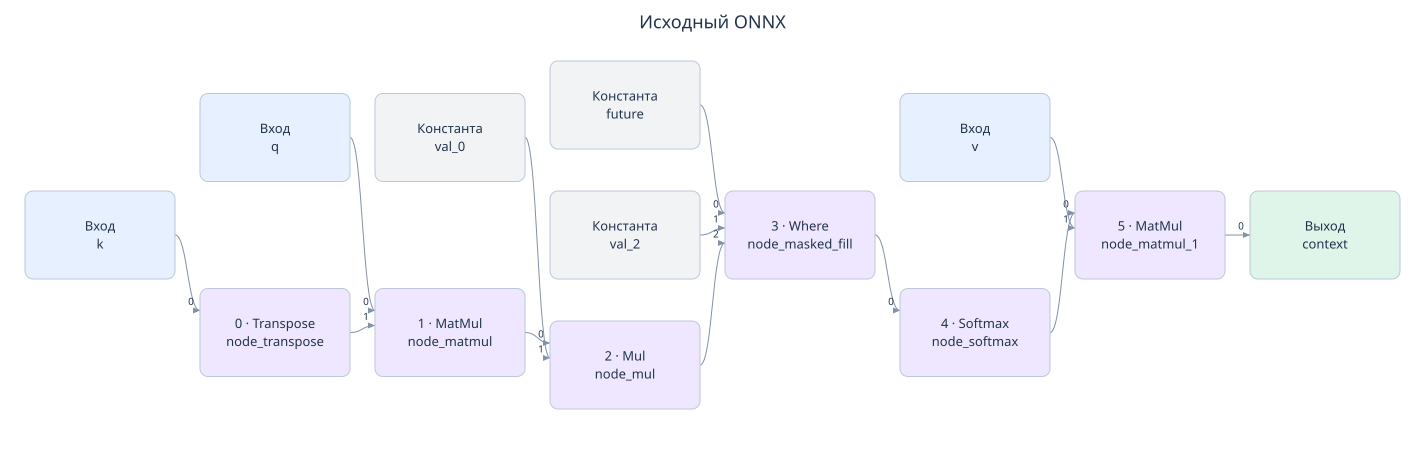

In [36]:
onnx_graph = attention_graph_edges(attn_model.graph)
save_json("attention-edges.json", onnx_graph)
show_graph(onnx_graph, "attention-onnx.svg", "Исходный ONNX")

### Эталон и таймер

Проверяем весь выход на двух наборах входов. Время измеряем на уже размещённых тензорах, без копирования CPU ↔ GPU.

In [37]:
attention_sync = sync_attention

def attention_timing(run):
    """Прогревает вызов без аргументов и возвращает p50 и p95 времени в мс."""
    for _ in range(10):
        run()
    attention_sync()
    # Синхронизация включает ожидание готового результата в каждый замер.
    times = []
    for _ in range(100):
        start = perf_counter()
        run()
        attention_sync()
        times.append((perf_counter() - start) * 1000)
    return {"p50": median(times), "p95": sorted(times)[ceil(0.95 * len(times)) - 1]}

`prepare` заранее связывает реализацию с входными буферами и возвращает вызов без аргументов. Проверка точности использует два набора данных, а таймер измеряет повторные вызовы на первом наборе, без подготовки входов.

In [38]:
def attention_row(name, prepare):
    """Проверяет выход на двух наборах входов и возвращает строку замеров."""
    # prepare привязывает уже размещённые тензоры и возвращает вызов без аргументов.
    max_error = 0.0
    for inputs, expected in attn_cases:
        run = prepare(inputs)
        actual = run().cpu()
        torch.testing.assert_close(actual, expected, atol=2e-5, rtol=1e-4)
        max_error = max(max_error, (actual - expected).abs().max().item())
    run = prepare(attn_cases[0][0])
    return {"name": name, "device": str(DEVICE), "error": max_error, **attention_timing(run)}

Сначала получим эталон и задержку PyTorch eager.

In [39]:
previous_precision = torch.get_float32_matmul_precision()
# Эталон FP32 считаем без ускорения матричных умножений через TF32.
torch.set_float32_matmul_precision("highest")
attn_cases = []
try:
    with torch.inference_mode():
        for cpu_inputs in (attn_cpu, fp32_inputs(29)):
            expected = eager_attention(*cpu_inputs)
            tensors = tuple(item.to(DEVICE).contiguous() for item in cpu_inputs)
            attn_cases.append((tensors, expected))
        eager_row = attention_row("PyTorch eager", lambda inputs: lambda: eager_attention(*inputs))
finally:
    torch.set_float32_matmul_precision(previous_precision)
save_json("attention-eager.json", eager_row)

### ONNX Runtime

Создадим сессию с CUDA Execution Provider. Отключим TF32 и переход на CPU, чтобы сравнение FP32 было честным.

In [40]:
def attention_session(profile=False):
    """Создаёт сессию ORT для DEVICE с сохранением графа или профиля."""
    options = ort.SessionOptions()
    options.intra_op_num_threads = torch.get_num_threads()
    options.enable_profiling = profile
    if profile:
        options.profile_file_prefix = str(OUT / "attention-ort-trace")
    else:
        options.optimized_model_filepath = str(attn_opt)
    # Запрещаем незаметное исполнение части графа на CPU.
    options.add_session_config_entry("session.disable_cpu_ep_fallback", "1")
    providers = [("CUDAExecutionProvider", {
        "device_id": str(torch.cuda.current_device()), "use_tf32": "0",
        "user_compute_stream": str(torch.cuda.current_stream(DEVICE).cuda_stream),
    })]
    session = ort.InferenceSession(str(attn_onnx), sess_options=options, providers=providers)
    if "CUDAExecutionProvider" not in session.get_providers():
        raise RuntimeError("ORT не загрузил CUDAExecutionProvider. Проверьте CUDA и cuDNN.")
    return session

Указание CUDA Execution Provider задаёт желаемый способ исполнения. Дополнительно проверяем поле `provider` у событий в профиле: так подтверждаем, что узлы графа действительно исполнялись через CUDA.

In [41]:
def require_cuda_placement(placement):
    """Проверяет, что профиль содержит узлы и все они исполнены на CUDA."""
    if not placement:
        raise RuntimeError("В профиле ORT нет исполненных узлов; GPU-прогон не подтверждён.")
    cpu_nodes = [row for row in placement if row[2] != "CUDAExecutionProvider"]
    if cpu_nodes:
        raise RuntimeError(f"ORT исполнил узлы вне CUDA: {cpu_nodes}")

IO binding связывает входы и выход ORT с готовыми буферами PyTorch.

In [42]:
def bind_attention_ort(session, inputs):
    """Привязывает буферы PyTorch к ORT и возвращает вызов без аргументов."""
    import numpy as np
    binding = session.io_binding()
    output = torch.empty_like(inputs[0])
    # Передаём адреса готовых буферов, чтобы исключить лишние копирования.
    for name, tensor in zip(attn_inputs, inputs):
        binding.bind_input(name, tensor.device.type, tensor.device.index or 0,
                           np.float32, tuple(tensor.shape), tensor.data_ptr())
    binding.bind_output(attn_result, output.device.type, output.device.index or 0,
                        np.float32, tuple(output.shape), output.data_ptr())

    def run():
        """Запускает ORT с привязанными буферами и возвращает тензор выхода."""
        session.run_with_iobinding(binding)
        return output
    return run

Буферы уже связаны с ORT через IO binding, поэтому на каждом вызове используются те же адреса входов и выхода. Сравниваем численный результат и измеряем задержку до готового тензора на том же устройстве.

In [43]:
attn_session = attention_session()
with torch.inference_mode():
    ort_row = attention_row("ONNX Runtime", lambda inputs: bind_attention_ort(attn_session, inputs))
save_json("attention-ort.json", ort_row)

2026-11-25 18:00:02.044534241 [W:onnxruntime:, inference_session.cc:2473 Initialize] Serializing optimized model with Graph Optimization level greater than ORT_ENABLE_EXTENDED and the NchwcTransformer enabled. The generated model may contain hardware specific optimizations, and should only be used in the same environment the model was optimized in.


Создаём отдельную сессию с профилированием и выполняем один вызов. Из событий извлекаем исполнителя каждого узла, а из сохранённого оптимизированного графа — состав операций после преобразований ORT.

In [44]:
profile_session = attention_session(profile=True)
bind_attention_ort(profile_session, attn_cases[0][0])()
attention_sync()
trace = Path(profile_session.end_profiling()).name
# По событиям узлов проверяем фактического исполнителя: CPU или CUDA.
placement = []
for event in read_json(trace):
    args = event.get("args", {})
    if event.get("cat") == "Node" and args.get("provider"):
        placement.append([event["name"], args.get("op_name", ""), args["provider"]])
require_cuda_placement(placement)
def op_counts(model):
    """Подсчитывает число узлов каждого типа операции в ONNX-модели."""
    return dict(Counter(node.op_type for node in model.graph.node))
save_json("attention-ort-profile.json", {
    "trace": trace, "placement": placement, "before": op_counts(attn_model),
    "after": op_counts(onnx.load(attn_opt)),
})

Число операций до и после оптимизации помогает заметить слияния и удаление лишних узлов. Сопоставьте число операций с измеренной задержкой.

In [45]:
ort_report = read_json("attention-ort-profile.json")
before, after = ort_report["before"], ort_report["after"]
show_table(["Операция", "В ONNX", "После оптимизации ORT"],
           [(op, before.get(op, 0), after.get(op, 0)) for op in sorted(before.keys() | after.keys())])
show_table(["Событие узла", "Операция", "Исполнитель"], ort_report["placement"])

| Операция | В ONNX | После оптимизации ORT |
| --- | --- | --- |
| FusedMatMul | 0 | 1 |
| MatMul | 2 | 1 |
| Mul | 1 | 0 |
| Softmax | 1 | 1 |
| Transpose | 1 | 0 |
| Where | 1 | 1 |

| Событие узла | Операция | Исполнитель |
| --- | --- | --- |
| node_matmul/MatmulTransposeFusion//MatMulScaleFusion/_kernel_time | FusedMatMul | CUDAExecutionProvider |
| node_masked_fill_kernel_time | Where | CUDAExecutionProvider |
| node_softmax_kernel_time | Softmax | CUDAExecutionProvider |
| node_matmul_1_kernel_time | MatMul | CUDAExecutionProvider |

### Граф после оптимизаций ONNX Runtime

Ниже — граф, сохранённый самой ORT. Сравните его с исходным: `FusedMatMul` может объединить транспонирование K, первое матричное умножение и масштабирование. Это оптимизации ORT; TensorRT далее независимо собирает движок из исходного ONNX.

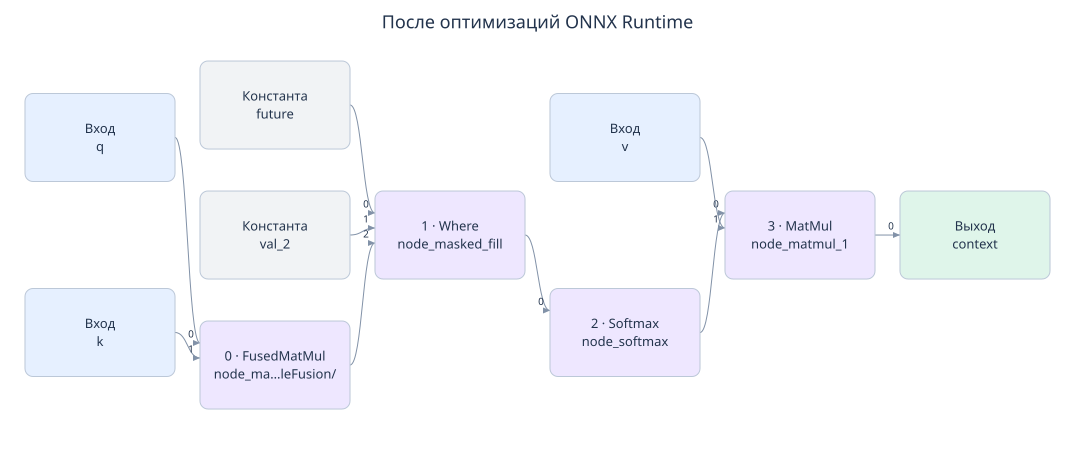

In [46]:
ort_model = onnx.load(attn_opt)
ort_graph = attention_graph_edges(ort_model.graph)
save_json("attention-ort-edges.json", ort_graph)
show_graph(ort_graph, "attention-ort.svg", "После оптимизаций ONNX Runtime")

В трассе ORT показаны события узлов графа и их исполнители. Отдельные CUDA-ядра подробнее видны в трассах PyTorch и TensorRT: эти представления дают разные уровни детализации.

In [47]:
# @title Какие узлы выполнились и в каком порядке?
show_trace(OUT / ort_report["trace"])

HTML-трасса: /home/jovyan/inference-results/20261125-145955-909198/attention-ort-trace_2026-11-25_18-00-02.json.html


### Что подтверждает профиль ONNX Runtime

**Запуск 25.11.2026 · FP32 · `[1, 4, 128, 64]`.** Исходные **6 узлов** стали **4**: `Transpose → MatMul → Mul` объединены в `FusedMatMul`; дальше идут `Where`, `Softmax`, `MatMul`.

Все четыре выполненных узла имеют `provider=CUDAExecutionProvider`. В профиле видны промежуточные scores и веса формы **`[1, 4, 128, 128]`**, по **256 КиБ** FP32. Таким образом, ORT выполнил fusion первой части графа, но здесь всё ещё материализует матрицы внимания.

События `Node` с суффиксом `_kernel_time` показывают время операторов на стороне ORT. В этом JSON нет событий CUDA `kernel`: длительность `FusedMatMul` в нём не является отдельным замером чистого GPU-ядра. Численную точность и p50 сравниваем по результатам общего таймера ниже.

### TensorRT

Соберём ONNX-граф в план для текущего GPU. Время сборки измеряем отдельно от инференса.

In [48]:
def release_tensorrt():
    """Освобождает контекст, движок, runtime и logger в порядке зависимостей."""
    names = ("attn_context", "attn_engine", "attn_runtime", "attn_logger")
    if any(name in globals() for name in names):
        torch.cuda.synchronize(DEVICE)
    for name in names:
        resource = globals().pop(name, None)
        del resource

Builder разбирает ONNX и выбирает реализации операций для текущего GPU и заданных форм. Полученный план сохраняем на диск; время сборки учитываем отдельно от времени повторного инференса.

In [49]:
def build_attention_plan(logger):
    """Собирает FP32-план TensorRT; возвращает путь к нему и время сборки в мс."""
    start = perf_counter()
    builder = trt.Builder(logger)
    network = builder.create_network(0)
    parser = trt.OnnxParser(network, logger)
    if not parser.parse_from_file(str(attn_onnx)):
        raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
    config = builder.create_builder_config()
    # Отключаем TF32 для сравнения FP32 и сохраняем сведения о слиянии слоёв.
    config.clear_flag(trt.BuilderFlag.TF32)
    config.profiling_verbosity = trt.ProfilingVerbosity.DETAILED
    plan = builder.build_serialized_network(network, config)
    if plan is None:
        raise RuntimeError("Не удалось собрать движок attention.")
    build_ms = (perf_counter() - start) * 1000
    path = OUT / "attention-fp32.plan"
    path.write_bytes(bytes(plan))
    return path, build_ms

Загрузим план. Контекст исполнения использует память и слои этого движка.

In [50]:
release_tensorrt()
try:
    attn_logger = trt.Logger(trt.Logger.WARNING)
    plan_path, build_ms = build_attention_plan(attn_logger)
    attn_runtime = trt.Runtime(attn_logger)
    attn_engine = attn_runtime.deserialize_cuda_engine(plan_path.read_bytes())
    if attn_engine is None:
        raise RuntimeError("Не удалось загрузить план TensorRT.")
    # План должен ожидать те же имена, формы и типы, что и экспортированный граф.
    for name in (*attn_inputs, attn_result):
        assert tuple(attn_engine.get_tensor_shape(name)) == attn_shape
        assert attn_engine.get_tensor_dtype(name) == trt.float32
except BaseException:
    release_tensorrt()
    raise

Движок хранит подготовленные вычисления, а execution context — состояние конкретного исполнения. Передаём ему адреса GPU-буферов и ставим запуск в текущий CUDA-поток; завершение учитывает синхронизация в таймере.

In [51]:
def bind_attention_trt(context, inputs):
    """Привязывает адреса тензоров к TensorRT и возвращает вызов без аргументов."""
    output = torch.empty_like(inputs[0])
    for name, tensor in zip((*attn_inputs, attn_result), (*inputs, output)):
        if not context.set_tensor_address(name, tensor.data_ptr()):
            raise RuntimeError(f"TensorRT отклонил адрес {name}")
    stream = torch.cuda.current_stream(DEVICE)
    def run():
        """Ставит вычисление в CUDA-поток и возвращает буфер выхода TensorRT."""
        if not context.execute_async_v3(stream.cuda_stream):
            raise RuntimeError("Ошибка запуска TensorRT.")
        return output
    return run

attn_context = attn_engine.create_execution_context()
if attn_context is None:
    raise RuntimeError("Не удалось создать контекст TensorRT.")
with torch.inference_mode():
    trt_row = attention_row("TensorRT", lambda inputs: bind_attention_trt(attn_context, inputs))
save_json("attention-trt.json", {**trt_row, "build_ms": build_ms})

[11/25/2026-18:00:07] [TRT] [W] Using default stream in enqueueV3() may lead to performance issues due to additional calls to cudaStreamSynchronize() by TensorRT to ensure correct synchronization. Please use non-default stream instead.


### Слои после сборки

Engine Inspector показывает слияния операций. Профилировщик TensorRT измеряет время каждого слоя.

In [52]:
class LayerTimes(trt.IProfiler):
    def __init__(self):
        """Создаёт хранилище замеров времени для каждого слоя TensorRT."""
        super().__init__()
        self.samples = defaultdict(list)

    def report_layer_time(self, name, ms):
        """Добавляет время одного выполнения слоя в миллисекундах."""
        self.samples[name].append(float(ms))

TensorRT вызывает `report_layer_time` после исполнения слоя. Собираем десять замеров после прогрева и связываем медиану времени с описанием слоя из Engine Inspector: один слой может соответствовать нескольким исходным операциям.

In [53]:
def attention_layer_report(engine, inputs):
    """Сопоставляет слои движка с исходными узлами и медианой времени в мс."""
    inspector = engine.create_engine_inspector()
    info = json.loads(inspector.get_engine_information(trt.LayerInformationFormat.JSON))
    save_json("attention-engine-inspector.json", info)
    profiler = LayerTimes()
    context = engine.create_execution_context()
    run = bind_attention_trt(context, inputs)
    run()
    attention_sync()
    # Сначала прогреваем контекст, затем собираем отдельные замеры каждого слоя.
    context.profiler = profiler
    context.enqueue_emits_profile = True
    for _ in range(10):
        run()
        attention_sync()
    return [[layer["Name"], layer.get("LayerType", "—"),
             layer.get("Metadata") or "—", round(median(profiler.samples[layer["Name"]]), 5)]
            for layer in info["Layers"] if profiler.samples[layer["Name"]]]

In [54]:
save_json("attention-layer-times.json", attention_layer_report(attn_engine, attn_cases[0][0]))
show_table(["Слой", "Тип", "Исходные узлы", "Медиана, мс"],
           read_json("attention-layer-times.json"))

[11/25/2026-18:00:07] [TRT] [W] Using default stream in enqueueV3() may lead to performance issues due to additional calls to cudaStreamSynchronize() by TensorRT to ensure correct synchronization. Please use non-default stream instead.


| Слой | Тип | Исходные узлы | Медиана, мс |
| --- | --- | --- | --- |
| __myl_Tra_myl0_0 | kgen | [ONNX Layer: node_transpose] | 0.0056 |
| fc_node_matmul_myl0_1 | gemm | [ONNX Layer: node_matmul] | 0.00819 |
| __myl_MulSelMaxSubExpSumDivMul_myl0_2 | kgen | [ONNX Layer: node_softmax][ONNX Layer: node_masked_fill][ONNX Layer: node_mul] | 0.00608 |
| fc_node_matmul_1_myl0_3 | gemm | [ONNX Layer: node_matmul_1] | 0.0096 |

### Граф готового TensorRT engine

TensorRT компилирует ONNX в бинарный план `.plan`. Структуру этого движка читаем через **Engine Inspector**: поле `Metadata` связывает слой с исходными ONNX-операциями, а `Inputs` и `Outputs` задают рёбра графа. Несколько исходных операций могут стать одним слоем. Подробности доступны благодаря `ProfilingVerbosity.DETAILED` при сборке. [Документация Engine Inspector](https://docs.nvidia.com/deeplearning/tensorrt/10.x.x/inference-library/engine-tools.html).

In [55]:
import re

def tensorrt_graph_edges(info, input_names, output_names):
    """Восстанавливает граф слоёв TensorRT из отчёта Engine Inspector."""
    labels, producer, edges = {}, {}, []
    for i, layer in enumerate(info["Layers"]):
        key = f"op:{i}"
        origins = re.findall(r"ONNX Layer: ([^\]]+)", layer.get("Metadata", ""))
        labels[key] = f"{i} · {layer['LayerType']}\n" + "\n".join(origins or [layer["Name"]])
        producer.update({tensor["Name"]: key for tensor in layer["Outputs"]})
    # Связываем реальные тензоры; веса без производителя показываем константами.
    for i, layer in enumerate(info["Layers"]):
        for slot, tensor in enumerate(layer["Inputs"]):
            name = tensor["Name"]
            if name not in producer:
                role = "input" if name in input_names else "const"
                producer[name] = role + ":" + name
                labels[producer[name]] = ("Вход" if role == "input" else "Константа") + "\n" + name
            edges.append((producer[name], f"op:{i}", name, slot))
    for name in output_names:
        labels["output:" + name] = "Выход\n" + name
        edges.append((producer[name], "output:" + name, name, 0))
    return {"labels": labels, "edges": edges}

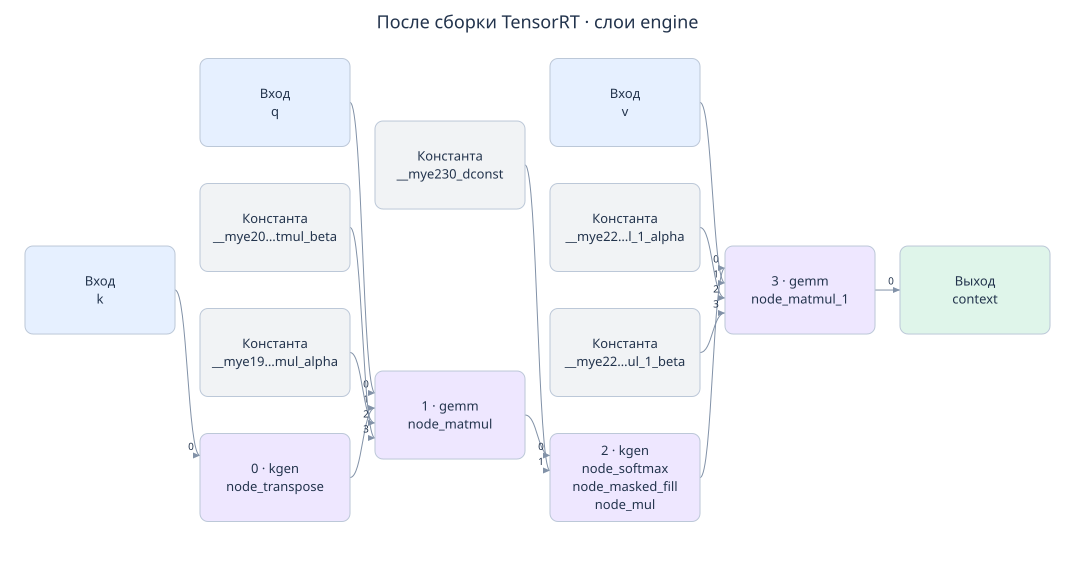

| Представление | Операций / слоёв | Файл |
| --- | --- | --- |
| Исходный ONNX | 6 | attention-fp32.onnx |
| После ORT | 4 | attention-fp32-ort.onnx |
| TensorRT engine | 4 | attention-fp32.plan |

In [56]:
engine_info = read_json("attention-engine-inspector.json")
trt_graph = tensorrt_graph_edges(engine_info, attn_inputs, (attn_result,))
save_json("attention-trt-edges.json", trt_graph)
show_graph(trt_graph, "attention-tensorrt.svg", "После сборки TensorRT · слои engine")
show_table(["Представление", "Операций / слоёв", "Файл"], [
    ["Исходный ONNX", len(attn_model.graph.node), attn_onnx.name],
    ["После ORT", len(ort_model.graph.node), attn_opt.name],
    ["TensorRT engine", attn_engine.num_layers, plan_path.name],
])

**Что находится в engine.** План хранит выбранные реализации операций и веса. Ниже показаны его размер и интерфейс входов/выходов. В раскрываемом JSON посмотрите `TacticName` (выбранная реализация), `Dimensions`, `Format/Datatype` и `Metadata`. Найдите слой, в котором объединились масштабирование, маска и softmax, и посмотрите его время в таблице профилирования.

In [57]:
from IPython.display import JSON

engine_io = []
for i in range(attn_engine.num_io_tensors):
    name = attn_engine.get_tensor_name(i)
    engine_io.append([name, str(attn_engine.get_tensor_mode(name)),
                      list(attn_engine.get_tensor_shape(name)), str(attn_engine.get_tensor_dtype(name))])
save_json("attention-engine-summary.json", {
    "plan": plan_path.name, "bytes": plan_path.stat().st_size,
    "layers": attn_engine.num_layers, "io": engine_io,
})
print(f"Engine: {plan_path.name} · {plan_path.stat().st_size / 1024:.1f} КиБ · {attn_engine.num_layers} слоя")
print("Файл плана:", plan_path)
show_table(["Тензор", "Режим", "Форма", "Тип"], engine_io)
display(JSON(engine_info, expanded=False))

Engine: attention-fp32.plan · 163.0 КиБ · 4 слоя
Файл плана: /home/jovyan/inference-results/20261125-145955-909198/attention-fp32.plan


| Тензор | Режим | Форма | Тип |
| --- | --- | --- | --- |
| q | TensorIOMode.INPUT | [1, 4, 128, 64] | DataType.FLOAT |
| k | TensorIOMode.INPUT | [1, 4, 128, 64] | DataType.FLOAT |
| v | TensorIOMode.INPUT | [1, 4, 128, 64] | DataType.FLOAT |
| context | TensorIOMode.OUTPUT | [1, 4, 128, 64] | DataType.FLOAT |

<IPython.core.display.JSON object>

Теперь расширяем границы наблюдения: входы копируются с CPU на GPU, выполняется TensorRT, выход возвращается на CPU. Три именованные области трассы показывают вклад передачи данных и самого вычисления.

In [58]:
try:
    # @title Полный вызов TensorRT: входы с CPU, вычисление и возврат выхода
    trt_trace_path = OUT / "attention-trt-request.json"
    activities = [torch.profiler.ProfilerActivity.CPU, torch.profiler.ProfilerActivity.CUDA]
    # Эта трасса включает передачи CPU ↔ GPU, в отличие от таблицы задержек.
    with torch.inference_mode(), torch.profiler.profile(activities=activities) as prof:
        with torch.profiler.record_function("Q, K, V -> GPU"):
            trace_inputs = tuple(t.to(DEVICE) for t in attn_cpu)
        with torch.profiler.record_function("TensorRT attention"):
            trace_output = bind_attention_trt(attn_context, trace_inputs)()
        with torch.profiler.record_function("context -> CPU"):
            trace_output.cpu()
    prof.export_chrome_trace(str(trt_trace_path))
    show_trace(trt_trace_path)
finally:
    release_tensorrt()

HTML-трасса: /home/jovyan/inference-results/20261125-145955-909198/attention-trt-request.json.html


### Сравнение FP32

У всех трёх реализаций одинаковые входы и границы таймера; выходы проверены по эталону.

In [59]:
attn_rows = [read_json(f"attention-{backend}.json") for backend in ("eager", "ort", "trt")]

show_table(["FP32", "Устройство", "p50, мс", "p95, мс", "Сборка, мс", "Макс. ошибка"],
           [(r["name"], r["device"], f"{r['p50']:.4f}", f"{r['p95']:.4f}",
             f"{r['build_ms']:.1f}" if "build_ms" in r else "—", f"{r['error']:.2g}")
            for r in attn_rows])
baseline = attn_rows[0]["p50"]
for row in attn_rows[1:]:
    change = (row["p50"] / baseline - 1) * 100
    print(f"{row['name']}: изменение медианы относительно PyTorch eager {change:+.1f}% "
          f"на форме {attn_shape}. Выход прошёл проверку FP32.")

| FP32 | Устройство | p50, мс | p95, мс | Сборка, мс | Макс. ошибка |
| --- | --- | --- | --- | --- | --- |
| PyTorch eager | cuda:0 | 0.0793 | 0.0856 | — | 3.6e-07 |
| ONNX Runtime | cuda:0 | 0.0395 | 0.0441 | — | 3.6e-07 |
| TensorRT | cuda:0 | 0.0239 | 0.0255 | 4434.8 | 3.6e-07 |

ONNX Runtime: изменение медианы относительно PyTorch eager -50.2% на форме (1, 4, 128, 64). Выход прошёл проверку FP32.
TensorRT: изменение медианы относительно PyTorch eager -69.9% на форме (1, 4, 128, 64). Выход прошёл проверку FP32.


### Что показали engine и трасса TensorRT

**Запуск 25.11.2026 · FP32 · `[1, 4, 128, 64]`.** В таблице — повторные вызовы с готовыми GPU-входами, без профилировщика.

| Реализация | p50, мкс | p95, мкс | Ускорение по p50 к eager |
|---|---:|---:|---:|
| PyTorch eager | 79.28 | 85.57 | 1.00× |
| ONNX Runtime | 39.50 | 44.06 | 2.01× |
| TensorRT | 23.88 | 25.49 | 3.32× |

Максимальная абсолютная ошибка у всех трёх — **3.58·10⁻⁷**. TensorRT собрал план за **4.435 с**, размер — **166 940 байт**, в engine **4 слоя**, внешние тензоры — FP32.

В GPU-трассе также **4 ядра**: транспонирование K (**1.888 мкс**), два GEMM (**10.752 мкс суммарно**), объединённые масштабирование, маска и softmax (**2.272 мкс**). Сумма — **14.912 мкс**, на GEMM приходится **72.1%**. ORT и TensorRT оставили по четыре операции/слоя, но объединили разные части вычисления: TensorRT сохраняет отдельное транспонирование и объединяет участок между двумя GEMM.

Полный профиль запроса включает переносы CPU↔GPU. В нём четыре CPU-вызова `cudaMemcpyAsync`, но только три соответствующих GPU-события копирования: у первого HtoD GPU-событие отсутствует. Поэтому сумма видимых копирований не описывает весь обмен. Послойный profiler и полный профиль запроса собраны отдельно от приведённых p50/p95.

## 4. Генерация текста под нагрузкой

Теперь измеряем всю Qwen3-0.6B: prefill обрабатывает промпт, decode выдаёт новые токены. Сравним eager, default и n-gram speculation.

### Continuous batching

В группе A и B. Когда B завершается, планировщик добавляет C, пока A продолжает генерацию. Сравним один и восемь запросов в полёте.

### Кеш общего префикса

SGLang (RadixAttention) и vLLM умеют повторно использовать KV-кеш общего начала запросов. Здесь кеш префиксов отключён; SGLang отдельно не измеряем.

### Несколько токенов за один проход

Учебная модель выбирает следующий токен по таблице. Проверим черновик продолжения «Положи книгу».

In [60]:
# В этой учебной модели следующий токен зависит только от предыдущего.
next_token = {"книгу": "на", "на": "стол", "стол": ".", "пол": "!", "!": "."}
prompt_tail = "книгу"
draft = ["на", "пол", "!"]

# Каждая позиция известного черновика становится входом для следующего предсказания.
predictions = [next_token[token] for token in [prompt_tail, *draft]]
print("Черновик:", draft)
print("Выбор основной модели по позициям:", predictions)

Черновик: ['на', 'пол', '!']
Выбор основной модели по позициям: ['на', 'стол', '!', '.']


Совпало только «на». После ошибки во второй позиции оставшийся черновик отбрасываем: его проверяли с неверным контекстом.

In [61]:
def verify_greedy(draft, predictions):
    """Возвращает принятый префикс и один токен основной модели."""
    for i, token in enumerate(draft):
        if token != predictions[i]:
            return draft[:i], predictions[i]
    return draft.copy(), predictions[len(draft)]  # Весь черновик совпал.


accepted, extra = verify_greedy(draft, predictions)
print("Принято из черновика:", accepted)
print("Выдано за проход:", [*accepted, extra])
print("Следующий токен после исправления:", next_token[extra])

Принято из черновика: ['на']
Выдано за проход: ['на', 'стол']
Следующий токен после исправления: .


За проход получили «на стол». При полном совпадении можно выдать весь черновик и ещё один токен. В vLLM вариант n-gram берёт черновик из повторов в контексте, без второй модели.

In [62]:
from contextlib import contextmanager
import signal
import socket
import time
from urllib.error import URLError
from urllib.request import urlopen

def available_port():
    '''Выбирает свободный порт для локального демо-сервера.'''
    with socket.socket() as listener:
        listener.bind(("127.0.0.1", 0))
        return listener.getsockname()[1]

### Сервер vLLM

По умолчанию используем Python текущего ядра. Для отдельного окружения задайте `VLLM_PYTHON`; для готовых весов — `INFERENCE_MODEL_PATH`. Иначе модель загрузится из Hugging Face при первом запуске.

In [63]:
LLM = "Qwen/Qwen3-0.6B"
MODEL_REVISION = "c1899de289a04d12100db370d81485cdf75e47ca"
PROMPTS = 96
VLLM_PYTHON = os.environ.get("VLLM_PYTHON", sys.executable)
VLLM_CMD = [VLLM_PYTHON, "-m", "vllm.entrypoints.cli.main"]
MODEL_PATH = os.environ.get("INFERENCE_MODEL_PATH")

Фиксируем одну ревизию модели и используем веса и токенизатор из одного каталога. Так различия между режимами сервера не смешиваются с изменениями модели или разной токенизацией.

In [64]:
vllm_version = subprocess.check_output([
    VLLM_PYTHON, "-c", "import importlib.metadata as m; print(m.version('vllm'))",
], text=True).strip()
if not MODEL_PATH:
    # Веса и токенизатор берём из одной фиксированной ревизии модели.
    download = ("from huggingface_hub import snapshot_download; import sys; "
                "print(snapshot_download(sys.argv[1], revision=sys.argv[2]))")
    MODEL_PATH = subprocess.check_output([
        VLLM_PYTHON, "-c", download, LLM, MODEL_REVISION,
    ], text=True).strip()
print("vLLM", vllm_version, "|", LLM)

vLLM 0.11.0 | Qwen/Qwen3-0.6B


Fetching 10 files: 100%|██████████| 10/10 [00:00<00:00, 3082.69it/s]


Во всех режимах одинаковы FP16, предел длины 512 токенов, бюджет GPU-памяти и максимум восемь активных последовательностей. Кеш общих префиксов отключён, чтобы повторное использование промптов не влияло на сравнение режимов.

In [65]:
def server_command(port, extra_args, profile_dir=None):
    """Собирает команду vLLM serve с общими настройками и флагами режима."""
    return [
        *VLLM_CMD, "serve", str(MODEL_PATH), "--served-model-name", LLM,
        "--tokenizer", str(MODEL_PATH),
        "--host", "127.0.0.1", "--port", str(port),
        "--dtype", "float16", "--max-model-len", "512", "--seed", "42",
        "--gpu-memory-utilization", "0.25", "--max-num-seqs", "8",
        "--max-num-batched-tokens", "2048", "--no-enable-prefix-caching",
        *extra_args,
    ]

In [66]:
def server_environment(profile_dir):
    """Возвращает копию окружения с настройками torch profiler для vLLM 0.11."""
    env = dict(os.environ)
    env.pop("VLLM_TORCH_PROFILER_DIR", None)
    if profile_dir is not None:
        env["VLLM_TORCH_PROFILER_DIR"] = str(profile_dir)
    env["VLLM_TORCH_PROFILER_WITH_STACK"] = "0"
    return env

Создание процесса ещё не означает готовность модели принимать запросы: сначала ждём успешного ответа `/health`. Сервер и его GPU-воркеры запускаются отдельной группой процессов, которую завершаем после эксперимента.

In [67]:
def wait_for_server(server, base_url, log_path):
    """Ждёт ответа от /health или показывает лог запуска."""

    deadline = time.monotonic() + 600
    while time.monotonic() < deadline and server.poll() is None:
        try:
            with urlopen(base_url + "/health", timeout=2) as response:
                if response.status == 200:
                    break
        except (URLError, TimeoutError):
            time.sleep(1)
    else:
        tail = "\n".join(log_path.read_text(errors="replace").splitlines()[-12:])
        raise RuntimeError(f"vLLM не запустился. {log_path}\n{tail}")

In [68]:
def stop_server(server, timeout=30.0):
    """Завершает всю группу, даже если главный процесс уже вышел."""
    try:
        os.killpg(server.pid, signal.SIGTERM)
    except ProcessLookupError:
        server.wait(timeout=5)
        return
    deadline = time.monotonic() + timeout
    while time.monotonic() < deadline:
        server.poll()  # Забираем код завершения лидера, не забывая его воркеров.
        try:
            os.killpg(server.pid, 0)
        except ProcessLookupError:
            break
        time.sleep(0.05)
    else:
        try:
            # После тайм-аута принудительно завершаем оставшихся GPU-воркеров.
            os.killpg(server.pid, signal.SIGKILL)
        except ProcessLookupError:
            pass
    server.wait(timeout=10)

In [69]:
@contextmanager
def llm_server(mode, extra_args, profile_dir=None):
    """Запускает сервер в своей группе процессов и всегда завершает его."""
    port = available_port()
    base_url = f"http://127.0.0.1:{port}"
    command = server_command(port, extra_args, profile_dir)
    log_path = OUT / f"server-{mode}.log"
    with log_path.open("w") as log:
        server = subprocess.Popen(
            command, stdout=log, stderr=subprocess.STDOUT,
            env=server_environment(profile_dir), start_new_session=True,
        )
        try:
            wait_for_server(server, base_url, log_path)
            yield base_url
        finally:
            stop_server(server)

Перед замером — 8 запросов прогрева, затем 96 измеряемых: целевая длина входа 256, выхода 32 токена. Фактическое число токенов после повторной токенизации смотрите в `total_input_tokens` и `total_output_tokens` в JSON.

In [70]:
def benchmark_command(base_url, concurrency, profiling, filename, warmup=False):
    """Собирает команду клиента для прогрева, замера или записи профиля."""
    command = [
        *VLLM_CMD, "bench", "serve",
        "--base-url", base_url, "--backend", "openai", "--endpoint", "/v1/completions",
        "--model", LLM, "--tokenizer", str(MODEL_PATH), "--dataset-name", "random", "--seed", "42",
        "--random-input-len", "256", "--random-output-len", "32", "--random-range-ratio", "0",
        "--ignore-eos", "--temperature", "0",
        "--max-concurrency", str(concurrency),
        "--num-prompts", str(8 if profiling or warmup else PROMPTS),
        "--percentile-metrics", "ttft,tpot", "--metric-percentiles", "95",
    ]
    if profiling and not warmup:
        command.append("--profile")
    elif not warmup:
        command += ["--save-result", "--result-dir", str(OUT), "--result-filename", filename]
    return command

Перед чтением метрик проверяем, что завершились все запросы и нет ошибок. В итоговую таблицу берём p95 времени до первого токена, p95 среднего времени на последующий токен и общий выпуск выходных токенов в секунду.

In [71]:
def read_vllm_result(filename, log_name, mode, concurrency):
    """Проверяет, что все запросы завершились, и выбирает метрики для таблицы."""

    result = read_json(filename)
    if result["completed"] != PROMPTS or result.get("failed", 0):
        raise RuntimeError(f"Часть запросов не завершилась. См. {log_name}.")
    return {
        "mode": mode,
        "concurrency": concurrency,
        "ttft": result["p95_ttft_ms"],
        "tpot": result["p95_tpot_ms"],
        "output_rate": result["output_throughput"],
    }

Прогрев проходит через тот же HTTP-интерфейс, что и измерение. Клиент измеряет обслуживание запроса целиком: на задержку влияют ожидание в очереди, работа модели и доставка ответа.

In [72]:
def bench_vllm(base_url, mode, concurrency, profiling=False):
    """Прогревает сервер и запускает клиент; возвращает метрики только для замера, не профиля."""
    filename = f"vllm-{mode}-{concurrency}.json"
    suffix = "-profile.log" if profiling else ".log"
    log_name = filename.removesuffix(".json") + suffix
    warmup_log = filename.removesuffix(".json") + "-warmup.log"
    # Прогрев идёт отдельным клиентом и не попадает в итоговый JSON замера.
    with (OUT / warmup_log).open("w") as log:
        subprocess.run(benchmark_command(base_url, concurrency, False, filename, warmup=True),
                       stdout=log, stderr=subprocess.STDOUT, check=True, timeout=600)
    with (OUT / log_name).open("w") as log:
        subprocess.run(benchmark_command(base_url, concurrency, profiling, filename),
                       stdout=log, stderr=subprocess.STDOUT, check=True, timeout=600)
    if not profiling:
        return read_vllm_result(filename, log_name, mode, concurrency)

N-gram speculation ищет в контексте совпадения длиной от одного до четырёх токенов и предлагает до трёх токенов продолжения. Основная модель проверяет черновик; выигрыш зависит от числа принятых предложений и расходов на проверку.

In [73]:
# Ищем совпадающие цепочки длиной от одного до четырёх токенов.
spec_config = {"method": "ngram", "prompt_lookup_min": 1, "prompt_lookup_max": 4,
               "num_speculative_tokens": 3}
modes = [
    ("eager", ["--enforce-eager"]),
    ("default", []),
    ("ngram", ["--speculative-config", json.dumps(spec_config)]),
]

Для каждого режима запускаем сервер заново, затем сравниваем один и восемь запросов в полёте. Измеряем, как параллелизм влияет на TTFT, TPOT и throughput.

In [74]:
rows = []
save_json("vllm-environment.json", {
    "version": vllm_version, "model": LLM, "revision": MODEL_REVISION,
    "prompts": PROMPTS, "input_tokens": 256, "output_tokens": 32,
    "warmup_prompts": 8, "max_num_seqs": 8,
    "cuda_visible_devices": os.environ.get("CUDA_VISIBLE_DEVICES", "all"),
})
# Каждый режим запускаем заново и проверяем при одинаковом параллелизме.
for mode, flags in modes:
    print(f"Запуск сервера vLLM: {mode}", flush=True)
    with llm_server(mode, flags) as base_url:
        for concurrency in (1, 8):
            print(f"vLLM {mode}, запросов в полёте: {concurrency}", flush=True)
            rows.append(bench_vllm(base_url, mode, concurrency))
            save_json("vllm.json", rows)

Запуск сервера vLLM: eager
vLLM eager, запросов в полёте: 1
vLLM eager, запросов в полёте: 8
Запуск сервера vLLM: default
vLLM default, запросов в полёте: 1
vLLM default, запросов в полёте: 8
Запуск сервера vLLM: ngram
vLLM ngram, запросов в полёте: 1
vLLM ngram, запросов в полёте: 8


Профиль сервера снимаем отдельным запуском: накладные расходы профилировщика не попадут в таблицу задержек.

In [75]:
def require_gpu_traces(directory):
    """Возвращает файлы с CUDA-ядрами в трассе; если их нет, вызывает ошибку."""
    import gzip
    candidates = sorted([*directory.rglob("*.json"), *directory.rglob("*.json.gz")])
    traces = []
    for path in candidates:
        opener = gzip.open if path.suffix == ".gz" else open
        with opener(path, "rt", encoding="utf-8") as handle:
            payload = json.load(handle)
        events = payload.get("traceEvents", []) if isinstance(payload, dict) else payload
        if any(event.get("cat") == "kernel" for event in events):
            traces.append(path)
    if not traces:
        raise RuntimeError(f"Профиль не содержит GPU-ядер: {directory}. Проверьте server-profile.log.")
    return traces

Профиль снимаем на восьми запросах в отдельном запуске сервера. После остановки проверяем наличие событий CUDA-ядер в записанной трассе.

In [76]:
attempt = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S-%f")
# Новая папка не позволяет принять старую трассу за результат этого запуска.
profile_dir = OUT / "vllm-trace" / attempt
profile_dir.mkdir(parents=True)
with llm_server("profile", [], profile_dir=profile_dir) as base_url:
    bench_vllm(base_url, "profile", concurrency=8, profiling=True)
gpu_traces = require_gpu_traces(profile_dir)
save_json("vllm-profile.json", {"directory": profile_dir.relative_to(OUT).as_posix(),
          "gpu_traces": [p.relative_to(OUT).as_posix() for p in gpu_traces]})

Выберите трассу воркера. Сначала в списке идут файлы с GPU-событиями.

In [77]:
# @title Открыть трассу vLLM
worker_index = 0  # @param {type:"integer"}
profile_manifest = read_json("vllm-profile.json")
trace_dir = OUT / profile_manifest["directory"]
gpu_trace_names = set(profile_manifest["gpu_traces"])
# Сначала показываем трассы с реальными GPU-событиями, затем остальные.
traces = sorted(
    [*trace_dir.rglob("*.json"), *trace_dir.rglob("*.json.gz")],
    key=lambda path: (path.relative_to(OUT).as_posix() not in gpu_trace_names,
                      "worker" not in path.name.lower(), str(path)),
)
for index, path in enumerate(traces):
    print(index, path.relative_to(trace_dir))
if 0 <= worker_index < len(traces):
    show_trace(traces[worker_index])
else:
    raise IndexError("Выберите номер трассы из списка выше.")

0 ekolodin-censor-0_459064.1795619187962531678.pt.trace.json.gz
1 ekolodin-censor-0_458920.async_llm.1795619187856176290.pt.trace.json.gz
HTML-трасса: /home/jovyan/inference-results/20261125-145955-909198/vllm-trace/20261125-150521-738488/ekolodin-censor-0_459064.1795619187962531678.pt.trace.json.gz.html


### Что выполнял GPU внутри vLLM

**Запуск 25.11.2026 · профиль `default` · 8 запросов, concurrency=8, после прогрева.** В трассе GPU-воркера **15 093 события `kernel`**, все на устройстве 0. Сумма их длительностей — **56.855 мс**.

| Семейство ядер | Сумма времени, мс | Доля времени ядер |
|---|---:|---:|
| GEMM и редукция split-K | 29.139 | 51.25% |
| Слитые операции Triton | 12.510 | 22.00% |
| Flash Attention, combine и подготовка | 11.589 | 20.38% |
| Запись KV-кеша | 2.631 | 4.63% |
| Остальные | 0.985 | 1.73% |

Группировка выполнена по именам ядер. Среди операций Triton видны нормализация, поэлементные преобразования и SiLU. Это ядра исполнения модели, созданные стеком vLLM/PyTorch; наше учебное `_triton_flash_forward` в модель не подключалось.

Есть **31 `cudaGraphLaunch`**, с которыми по `correlation` связаны **13 919 исполнений GPU-ядер**. CUDA Graph сокращает число отдельных команд запуска на CPU; сами вычислительные ядра продолжают выполняться. Видны `FlashAttnFwdSm90`, `FlashAttnFwdCombine` и **924** вызова `reshape_and_cache_flash_kernel` — attention и запись K/V в кеш действительно выполняются на GPU.

В трассе `async_llm` GPU-ядер нет: вычисления модели видны в файле воркера. Доли таблицы относятся к сумме времени ядер этого профиля. Клиентские TTFT/TPOT и throughput измерены в отдельных сериях по 96 запросов.

## 5. Что изменилось?

p50 — медиана; p95 — граница для 95% вызовов. Сравнивайте одинаковые форму, точность и нагрузку.

In [78]:
longest = max(r["length"] for r in attention_rows)
long_rows = [r for r in attention_rows if r["length"] == longest]
base = next(r for r in long_rows if r["backend"] == "eager-explicit")
for r in long_rows:
    if r["backend"] != base["backend"]:
        print(f"L={longest}: {r['backend']}, ускорение по p50 {base['p50_ms'] / r['p50_ms']:.2f}×. "
              f"Разница пиков (eager минус этот режим): {base['peak_mib'] - r['peak_mib']:.2f} МиБ.")

L=1024: sdpa-flash, ускорение по p50 2.48×. Разница пиков (eager минус этот режим): 20.42 МиБ.
L=1024: triton-flash, ускорение по p50 1.77×. Разница пиков (eager минус этот режим): 24.50 МиБ.


TTFT — время до первого токена; TPOT — среднее время на токен после первого; throughput — общий выпуск токенов в секунду.

In [79]:
vllm_rows = read_json("vllm.json")
show_table(
    ["vLLM", "Запросов в полёте", "TTFT p95, мс", "TPOT p95, мс/токен", "Выходных токенов/с"],
    [(r["mode"], r["concurrency"], f"{r['ttft']:.2f}", f"{r['tpot']:.2f}",
      f"{r['output_rate']:.1f}") for r in vllm_rows],
)

| vLLM | Запросов в полёте | TTFT p95, мс | TPOT p95, мс/токен | Выходных токенов/с |
| --- | --- | --- | --- | --- |
| eager | 1 | 14.62 | 7.18 | 139.7 |
| eager | 8 | 43.41 | 7.88 | 979.9 |
| default | 1 | 20.07 | 2.11 | 399.3 |
| default | 8 | 73.19 | 3.34 | 1987.5 |
| ngram | 1 | 14.19 | 2.41 | 569.9 |
| ngram | 8 | 36.21 | 6.49 | 1911.9 |

Как изменились TTFT и throughput при росте параллелизма? Окупился ли черновик на случайных входах?

In [80]:
for concurrency in (1, 8):
    runs = {row["mode"]: row for row in vllm_rows if row["concurrency"] == concurrency}
    before, after = runs["default"]["tpot"], runs["ngram"]["tpot"]
    print(f"Запросов в полёте: {concurrency}. Время на токен (p95): "
          f"{before:.2f} мс без черновика и {after:.2f} мс с черновиком.")

Запросов в полёте: 1. Время на токен (p95): 2.11 мс без черновика и 2.41 мс с черновиком.
Запросов в полёте: 8. Время на токен (p95): 3.34 мс без черновика и 6.49 мс с черновиком.


### Как читать результаты vLLM этого запуска

**Запуск 25.11.2026.** Во всех шести сериях завершились **96 запросов**, получено **3072 выходных токена**. В логах eager: `compilation level=0`, CUDA Graphs отключены; в default: `level=3`, включены компиляция и CUDA Graphs. Сравнение показывает совместный эффект этих оптимизаций.

**Default относительно eager:** throughput вырос **139.69 → 399.26 токенов/с** при concurrency=1 и **979.92 → 1987.51** при concurrency=8. TPOT p95 сократился **7.18 → 2.11 мс** и **7.88 → 3.34 мс**. При этом TTFT p95 вырос **14.62 → 20.07 мс** и **43.41 → 73.19 мс**: ускорение продолжения ответа не означает сокращение ожидания первого токена.

**Ngram относительно default:**

| Запросов в полёте | Throughput, токенов/с | Средний TPOT, мс | TPOT p95, мс | TTFT p95, мс |
|---|---:|---:|---:|---:|
| 1 | 399.26 → 569.87 | 2.103 → 1.370 | 2.114 → 2.406 | 20.07 → 14.19 |
| 8 | 1987.51 → 1911.94 | 2.656 → 3.498 | 3.343 → 6.488 | 73.19 → 36.21 |

При **одном запросе** throughput вырос на **42.7%**, средний TPOT снизился на **34.8%**, а TPOT p95 вырос на **13.8%**. Медиана TPOT также снизилась: **2.103 → 1.117 мс**. Среднее и медиана уменьшились, а верхняя часть распределения задержек выросла; p95 и общий throughput описывают разные свойства нагрузки.

При **восьми запросах** ngram дал **−3.8% throughput** и **+94.1% TPOT p95**, одновременно уменьшив TTFT p95 примерно вдвое. На этой нагрузке default лучше по throughput и TPOT p95, ngram — по TTFT p95.

В `server-ngram.log` за интервал с отметкой **18:04:52** принято **1395 из 2178** предложенных токенов (**64.0%**): черновики действительно принимаются. Это интервальный счётчик логирования; он не задаёт общую долю для каждой отдельной серии. GPU-профиль записан только для default, поэтому распределение GPU-времени выше относится к этому режиму.

Сначала выбирайте режимы с приемлемым TTFT, затем сравнивайте throughput. На случайных данных мало повторов: сравните время поиска и проверки черновика с выигрышем от принятых токенов. Архив ниже содержит результаты и трассы текущего запуска.

In [81]:
# Архив лежит рядом с каталогом и содержит уже снятые профили и числа.
archive = shutil.make_archive(str(OUT), "zip", root_dir=OUT.parent, base_dir=OUT.name)
print("Архив результатов:", archive)

Архив результатов: /home/jovyan/inference-results/20261125-145955-909198.zip


### Документация

- [PyTorch Profiler](https://docs.pytorch.org/tutorials/recipes/recipes/profiler_recipe.html)
- [FlashAttention и аппаратная поддержка](https://github.com/Dao-AILab/flash-attention)
- [Scaled dot product attention в PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html)
- [ONNX Runtime I/O Binding](https://onnxruntime.ai/docs/performance/tune-performance/iobinding.html)
- [TensorRT Runtime API](https://docs.nvidia.com/deeplearning/tensorrt/latest/inference-library/python-api-docs.html)
- [Бенчмарк vLLM](https://docs.vllm.ai/en/v0.11.0/cli/bench/serve/)
- [Профилирование vLLM](https://docs.vllm.ai/en/stable/contributing/profiling/)
- [Оптимизации графа в ONNX Runtime](https://onnxruntime.ai/docs/performance/graph-optimizations)
- [TensorRT Engine Inspector](https://docs.nvidia.com/deeplearning/tensorrt/10.x.x/inference-library/engine-tools.html)
- [Speculative decoding и правило проверки](https://proceedings.mlr.press/v202/leviathan23a.html)
- [Поиск черновика по n-граммам в vLLM](https://github.com/vllm-project/vllm/blob/v0.11.0/docs/features/speculative_decoding/n_gram.md)
- [Карточка Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B)
- [Просмотр трасс в VizTracer](https://github.com/gaogaotiantian/viztracer)
- [Triton: fused attention](https://triton-lang.org/main/getting-started/tutorials/06-fused-attention.html)